In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from behavior_fw.io.load_dataset import load_experiment_dataset
from behavior_fw.core.dataset import create_experiments_metadata, select_exp_condition

from behavior_fw.utils.psth import extract_experiment_psth
from behavior_fw.analysis.calc_velocities import get_velocities
# from behavior_fw.visualization.plot_density import (
#     plot_dynamic_cartesian_densities,
#     plot_dynamic_polar_densities,
# )
from behavior_fw.visualization.plot_psth import (
    plot_condition_psth_summary,
    plot_single_experiment_psth,
)
from behavior_fw.visualization.plot_trajectory import plot_single_fly_trajectory, plot_multi_experiment_split_trajectories

In [2]:
path_dir_data = Path("/home/athira/CF/PhD/Data")
# path_dir_dataset  = path_dir_data / "FW_Darkness_Bonsai_08082026" 
path_dir_dataset  = path_dir_data / "LocalSearch_OptoCL" 

In [3]:
path_to_metadata = path_dir_dataset / "metadata.csv"
df_metadata = pd.read_csv(path_to_metadata,index_col=0 )
df_metadata

,folder_name,folder_path,date,time,datetime,genotype,protocol,medium,center
0,20260814_165206_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,165206,2026-08-14 16:52:06,Gr43a,OptoCL,ATR,300
1,20260814_171722_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,171722,2026-08-14 17:17:22,Gr43a,OptoCLReplay,ATR,300
2,20260815_095930_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,95930,2026-08-15 9:59:30,Gr43a,OptoCL,ATR,300
3,20260815_102821_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,102821,2026-08-15 10:28:21,Gr43a,OptoCLReplay,ATR,300
4,20260815_110148_Gr43a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,110148,2026-08-15 11:01:48,Gr43a,OptoCL,NR,300
...,...,...,...,...,...,...,...,...,...
116,20260927_214323_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,214323,2026-09-27 21:43:23,Gr5a,OptoCL,ATR,300
117,20260927_220910_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,220910,2026-09-27 22:09:10,Gr5a,OptoCL,NR,300
118,20260927_223457_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,223457,2026-09-27 22:34:57,Gr5a,OptoCL,NR,300
119,20260927_225846_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,225846,2026-09-27 22:58:46,Gr5a,OptoCL,NR,300


In [4]:
df_Gr5a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr5a", protocol="OptoCL", medium="ATR", zone="300")
df_Gr43a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="ATR", zone="300")
df_Gr5a_NR_CL = select_exp_condition(df_metadata, genotype="Gr5a", protocol="OptoCL", medium="NR", zone="300")
df_Gr43a_NR_CL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="NR", zone="300")
# Loads processed CSVs if they exist, or calculates LOWESS once and caches to disk
dataset_Gr5a_ATR_CL = load_experiment_dataset(df_Gr5a_ATR_CL, fps=60.0)
print(f"Loaded {len(dataset_Gr5a_ATR_CL)} flies into memory!")
print("Columns in df_track:", dataset_Gr5a_ATR_CL[0]["df_track"].columns.tolist())

dataset_Gr43a_ATR_CL = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0)
dataset_Gr5a_NR_CL = load_experiment_dataset(df_Gr5a_NR_CL, fps=60.0)
dataset_Gr43a_NR_CL = load_experiment_dataset(df_Gr43a_NR_CL, fps=60.0)


Loaded 38 flies into memory!
Columns in df_track: ['Index', 'X_cal', 'Y_cal', 'ori_angle_cal', 'X_px', 'Y_px', 'ori_angle', 'LowResTimestampTick', 'LowResFrameNumber', 'HighResFrameNumber', 'X', 'Y', 'LEDstate', 'Vf_smooth', 'Vs_smooth', 'Vr_smooth', 'Vt_smooth', 'Vr_abs']


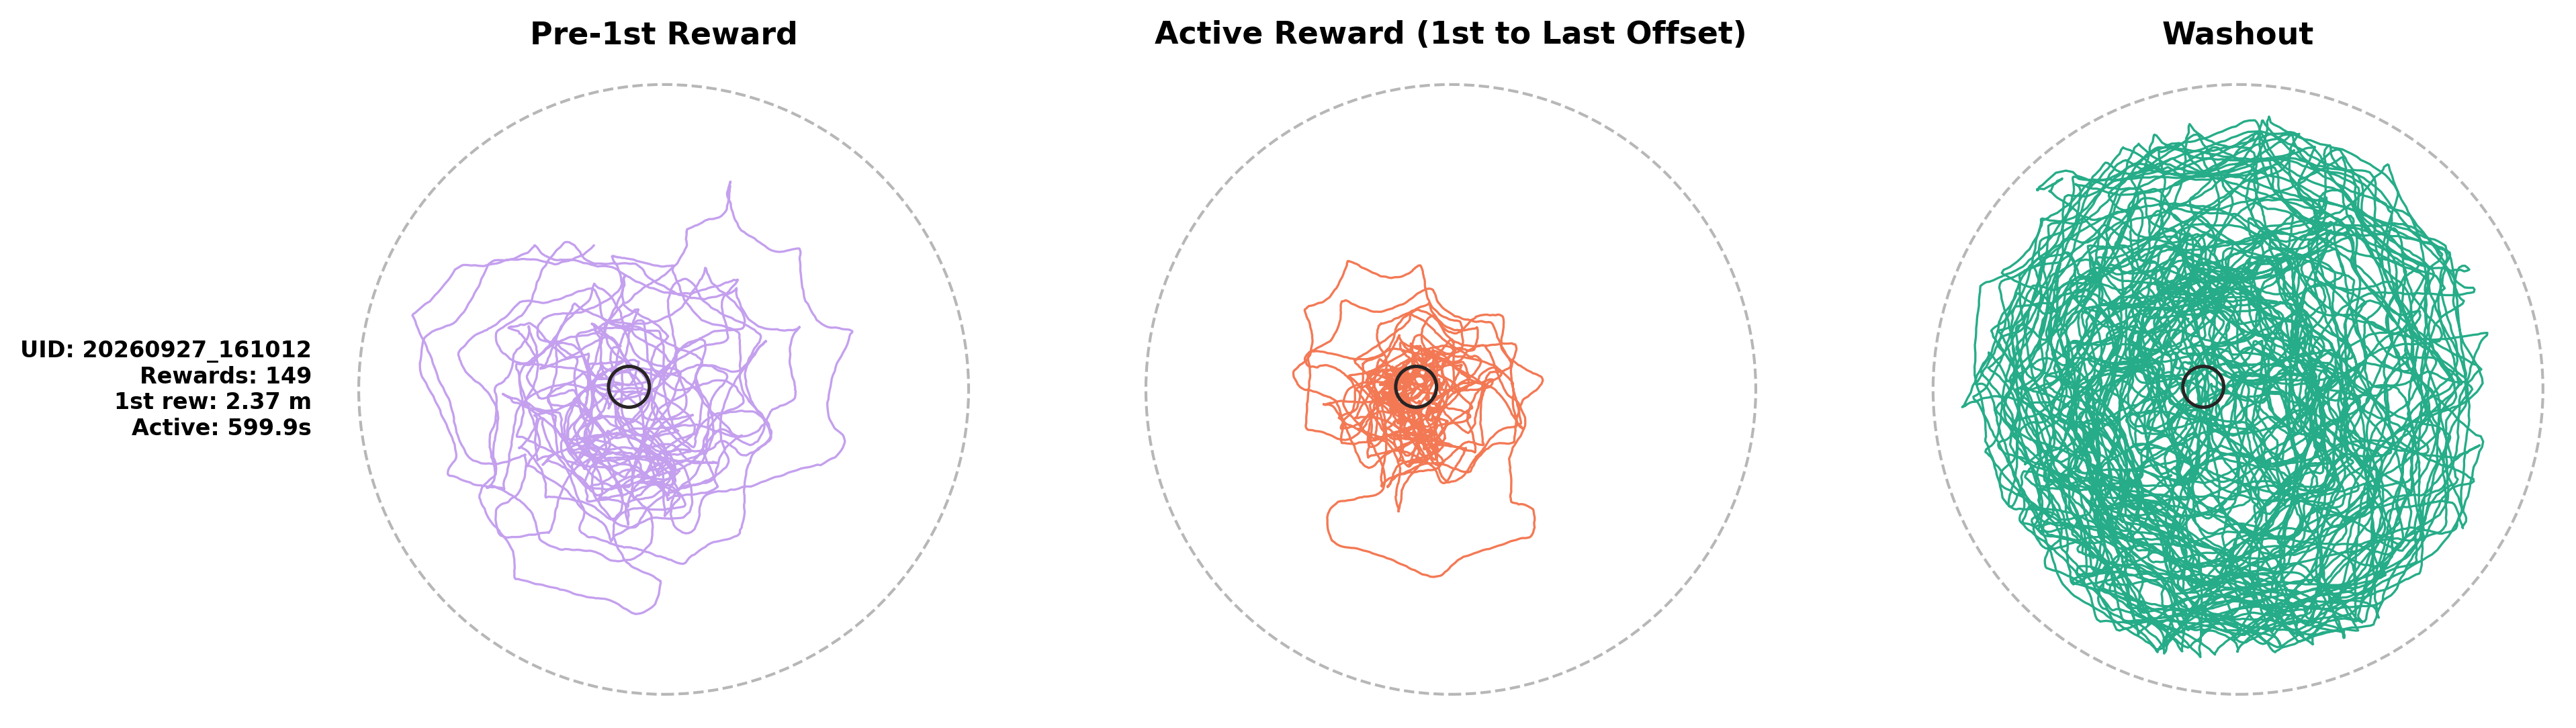

In [5]:
color_map = {
    "Baseline": "#BA90EB", 
    "Stimulus": "#F16237", 
    "Washout": '#009E73'
}

fig, axes = plot_multi_experiment_split_trajectories(
    dataset=[dataset_Gr5a_ATR_CL[30]],      
    color_map=color_map,
    arena_r=45.0,
    fps=60.0
)

In [6]:
# fig.savefig("ex_trajectory.png")

In [7]:
# # from behavior_fw.visualization.plot_trajectory import plot_multi_experiment_split_trajectories
# # Define your palette map
# color_map = {
#     "Baseline": "#BA90EB", 
#     "Stimulus": "#F16237", 
#     "Washout": '#009E73'
# }

# # Run the plot function across all loaded fly experiments
# fig, axes = plot_multi_experiment_split_trajectories(
#     dataset=dataset_Gr5a_ATR_CL[5:],      
#     color_map=color_map,
#     arena_r=45.0,
#     fps=60.0
# )

# # fig.savefig("split_trajectories_by_period.svg")

In [8]:
# Imports
from behavior_fw.visualization.plot_density import (
    plot_single_experiment_cartesian_density,
    plot_dataset_average_cartesian_density,
    plot_compare_conditions_cartesian,
    plot_single_experiment_polar_density,
    plot_dataset_average_polar_density,
    plot_compare_conditions_polar,
)


In [ ]:
# dataset_Gr5a_ATR_CL[0]["zone_X"], dataset_Gr5a_ATR_CL[0]["zone_Y"], dataset_Gr5a_ATR_CL[0]["zone_r"]

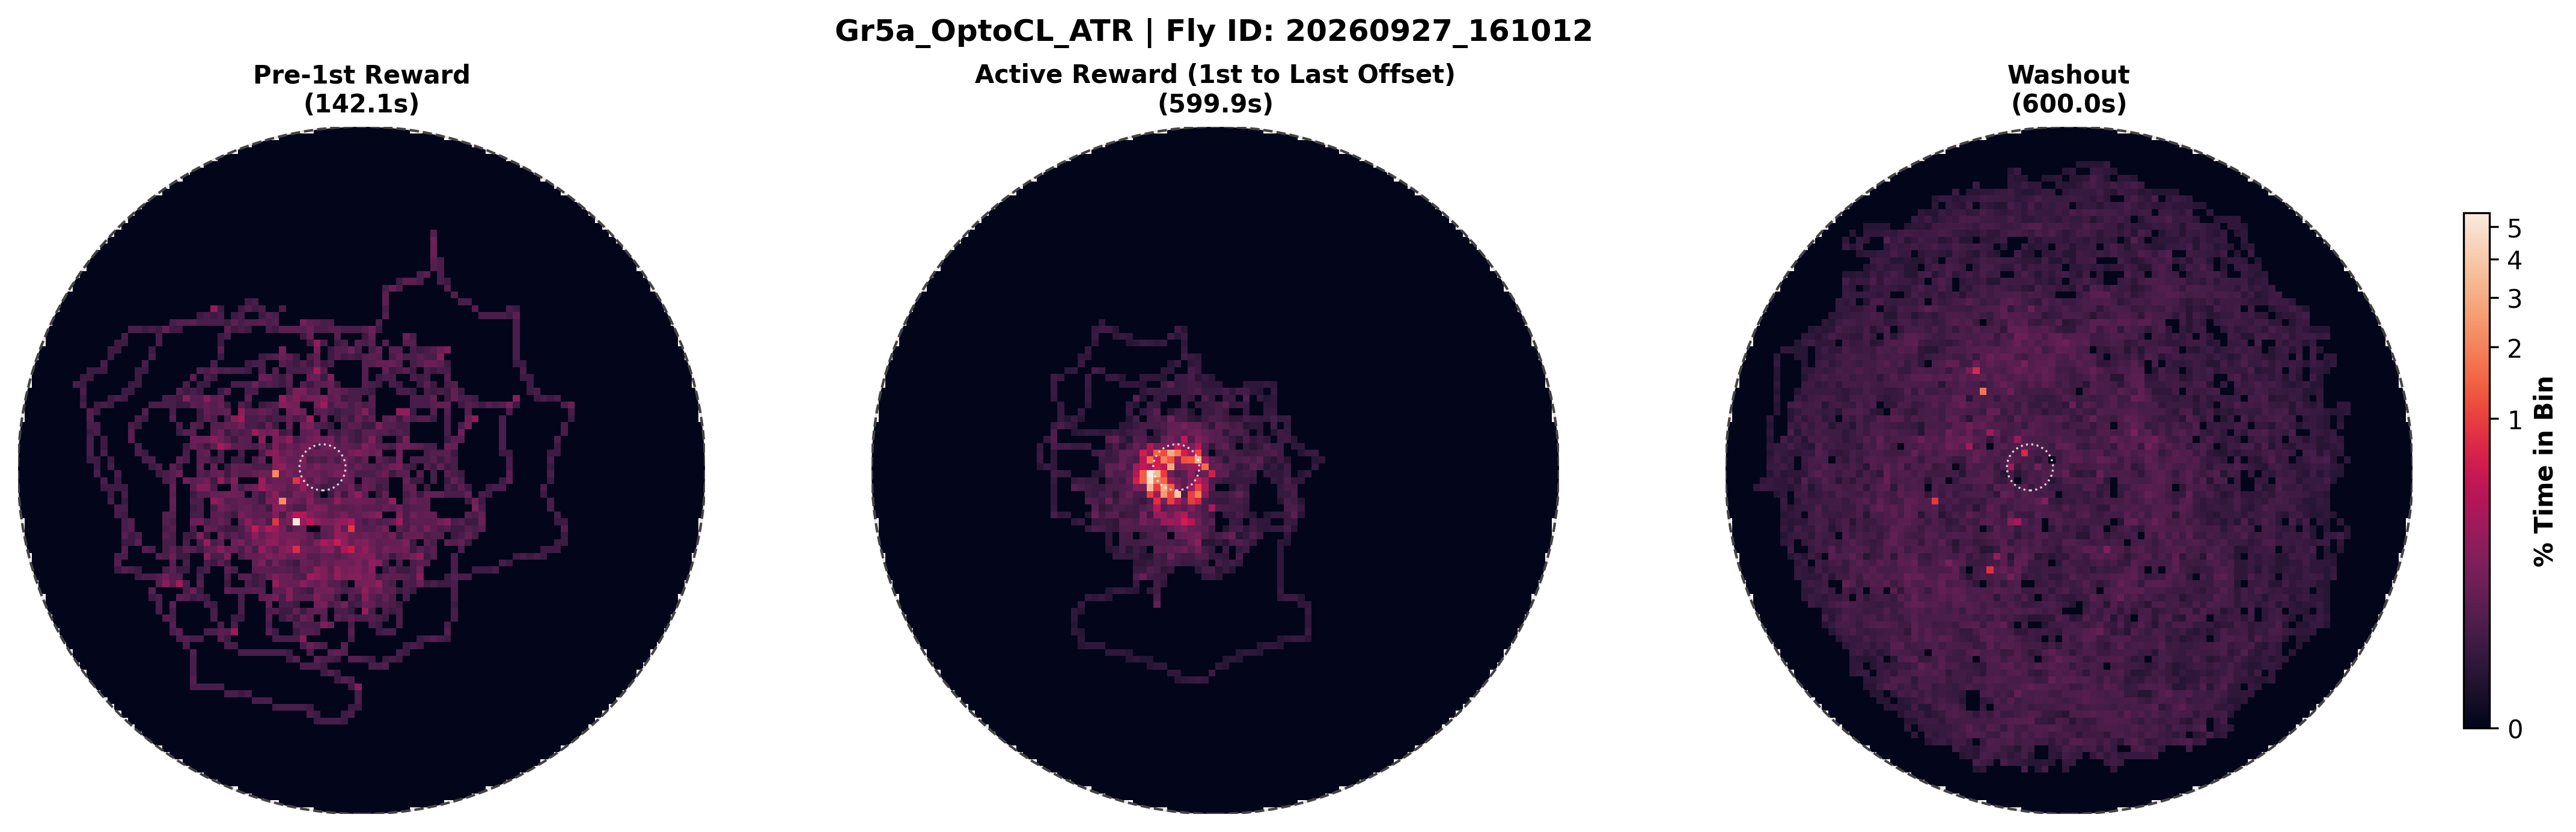

In [9]:

# 1.a) Single Cartesian Experiment Plot
fig, ax = plot_single_experiment_cartesian_density(
    dataset=dataset_Gr5a_ATR_CL, 
    exp_idx=30, 
    dataset_name="Gr5a_OptoCL_ATR"
)


In [ ]:

# 1.a) Single Cartesian Experiment Plot
fig, ax = plot_single_experiment_cartesian_density(
    dataset=dataset_Gr5a_NR_CL, 
    exp_idx=0, 
    dataset_name="Gr5a_OptoCL_NR"
)


In [ ]:

# 1.b) Dataset Average Cartesian Plot
fig, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr43a_NR_CL, 
    dataset_name="Gr43a_OptoCL_NR"
)


In [ ]:
# fig.savefig("dataset_density_Gr43a_NR.png")

In [ ]:

# 1.b) Dataset Average Cartesian Plot
fig, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr5a_NR_CL, 
    dataset_name="Gr5a_OptoCL_NR"
)
# fig.savefig("dataset_density_Gr5a_NR.png")

In [5]:
df_Gr43a_ATR_CL_LL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="ATR", zone="LL")
df_Gr43a_NR_CL_LL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="NR", zone="LL")
dataset_Gr43a_ATR_CL_LL = load_experiment_dataset(df_Gr43a_ATR_CL_LL, fps=60.0)
dataset_Gr43a_NR_CL_LL = load_experiment_dataset(df_Gr43a_NR_CL_LL, fps=60.0)

print(len(df_Gr43a_ATR_CL_LL.index))


# 1.b) Dataset Average Cartesian Plot
fig1, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr43a_ATR_CL_LL, 
    dataset_name="Gr43a_OptoCL_ATR_LL")

# 1.b) Dataset Average Cartesian Plot
fig2, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr43a_NR_CL_LL, 
    dataset_name="Gr43a_OptoCL_NR_LL")

5


NameError: name 'plot_dataset_average_cartesian_density' is not defined

In [ ]:
# fig1.savefig("dataset_density_Gr43a_LL_ATR.png")
# fig2.savefig("dataset_density_Gr43a_LL_NR.png")

6


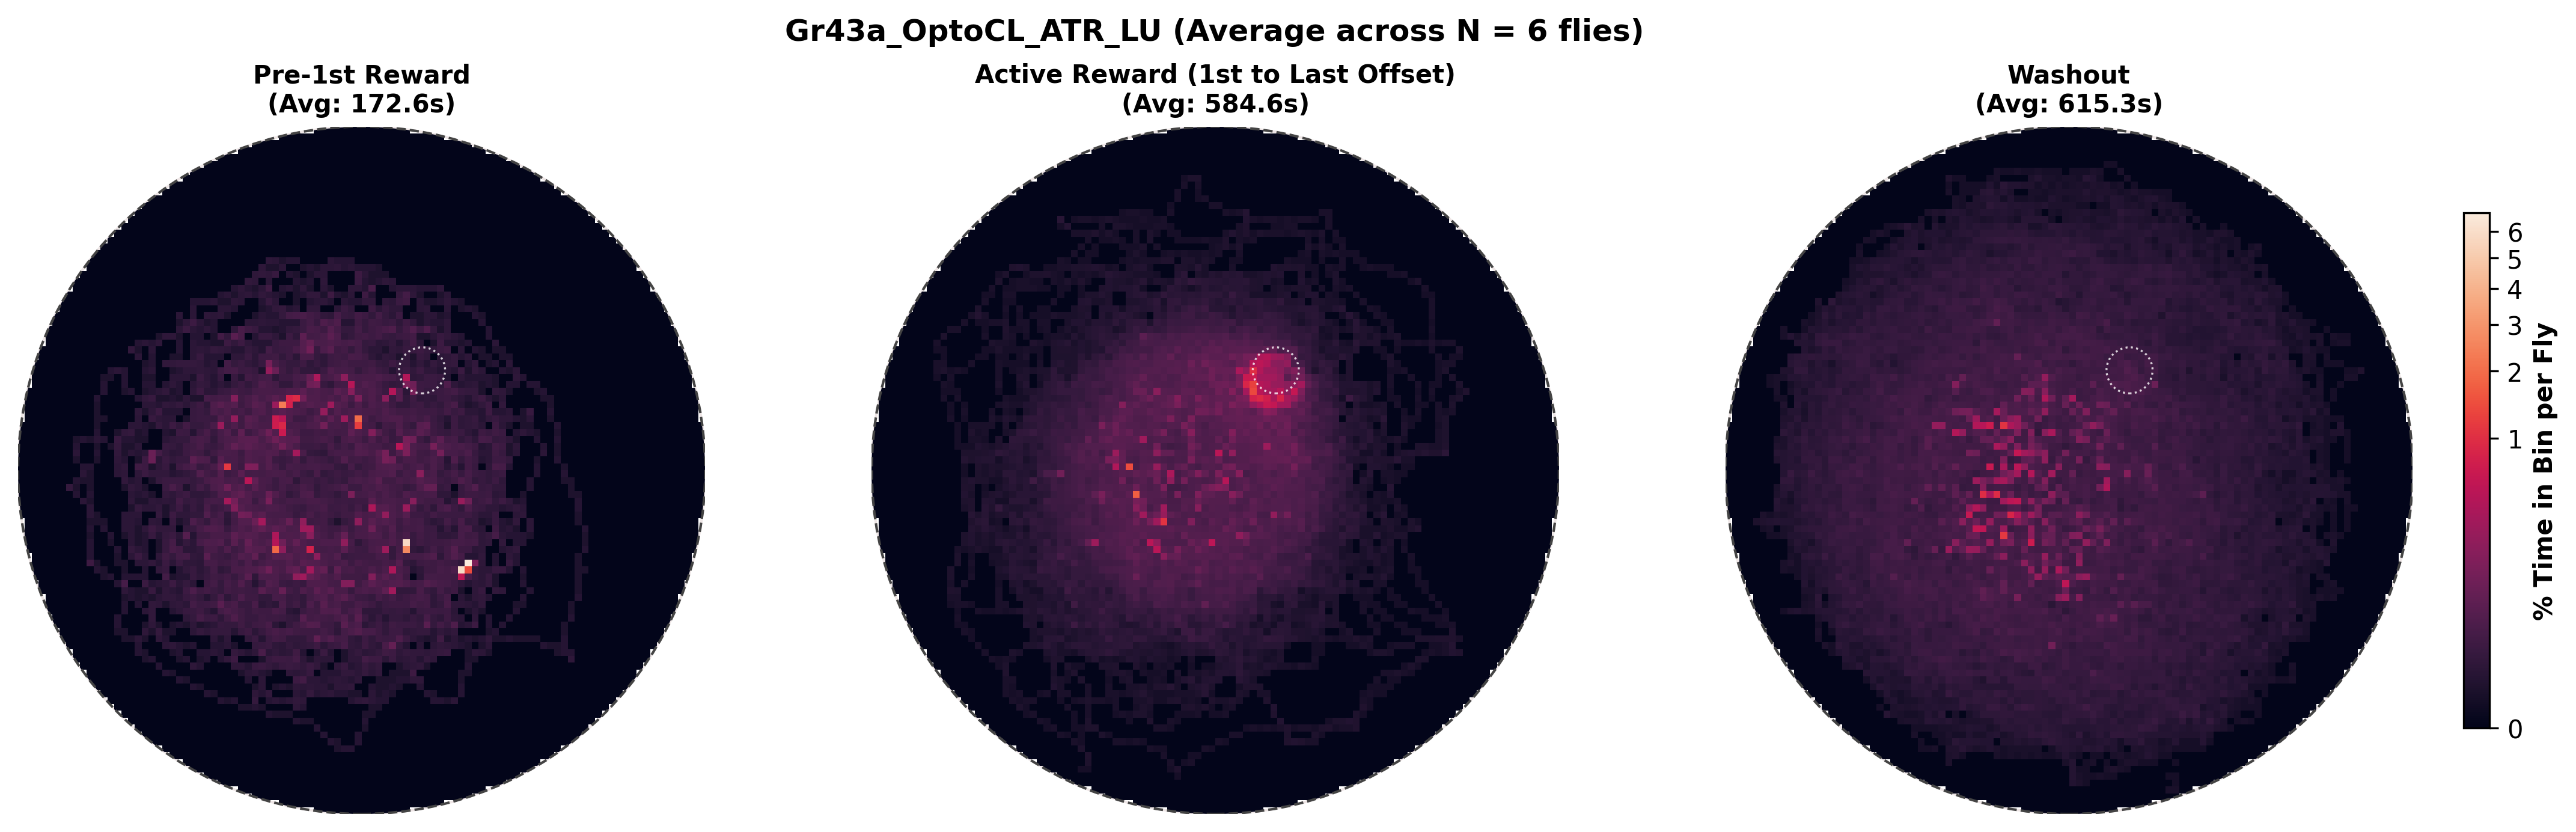

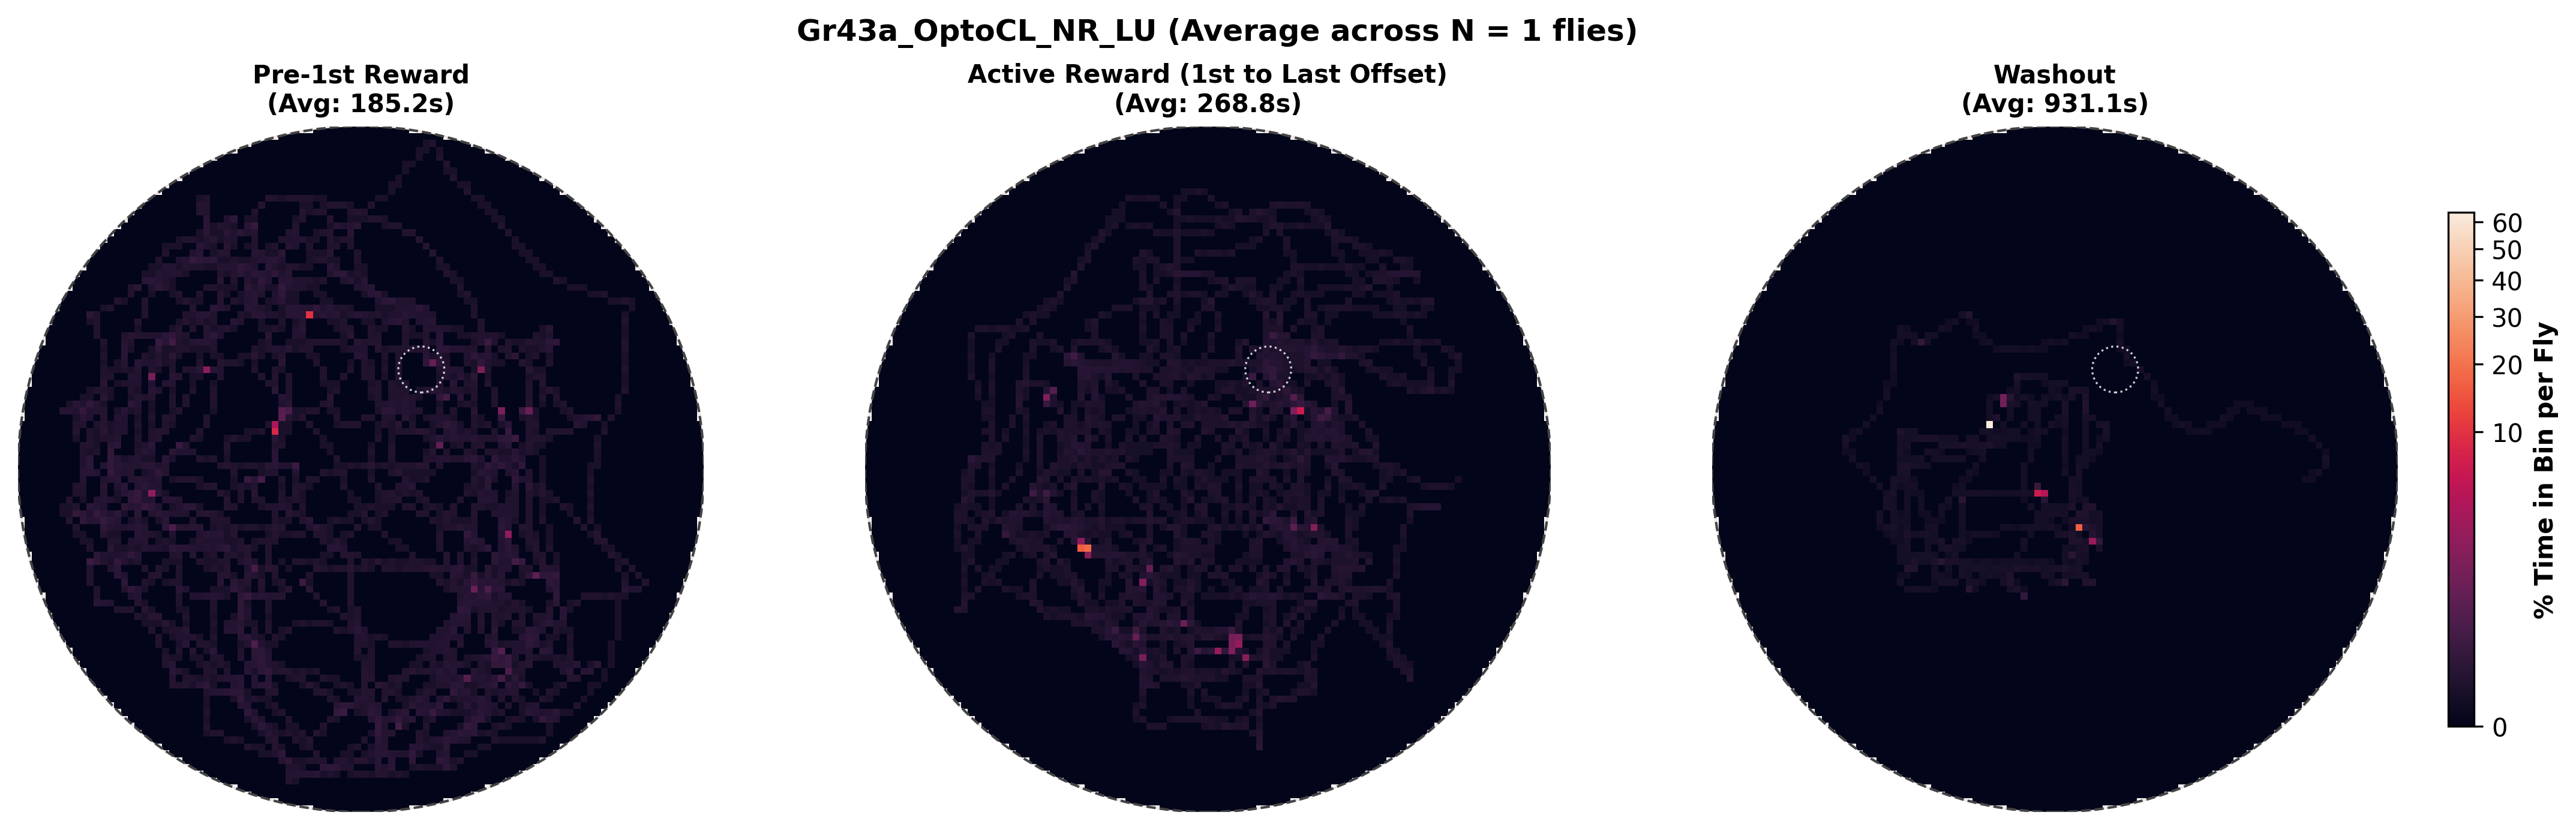

In [ ]:
df_Gr43a_ATR_CL_LU = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="ATR", zone="LU")
df_Gr43a_NR_CL_LU = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="NR", zone="LU")
dataset_Gr43a_ATR_CL_LU = load_experiment_dataset(df_Gr43a_ATR_CL_LU, fps=60.0)
dataset_Gr43a_NR_CL_LU = load_experiment_dataset(df_Gr43a_NR_CL_LU, fps=60.0)

print(len(df_Gr43a_ATR_CL_LU.index))


# 1.b) Dataset Average Cartesian Plot
fig1, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr43a_ATR_CL_LU, 
    dataset_name="Gr43a_OptoCL_ATR_LU")

# 1.b) Dataset Average Cartesian Plot
fig2, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr43a_NR_CL_LU, 
    dataset_name="Gr43a_OptoCL_NR_LU")

In [ ]:
# fig1.savefig("dataset_density_Gr43a_LU_ATR.png")
# fig2.savefig("dataset_density_Gr43a_LU_NR.png")

In [ ]:

# 1.a) Single Cartesian Experiment Plot
fig, ax = plot_single_experiment_cartesian_density(
    dataset=dataset_Gr5a_ATR_CL, 
    exp_idx=30, 
    dataset_name="Gr5a_OptoCL_ATR"
)


5


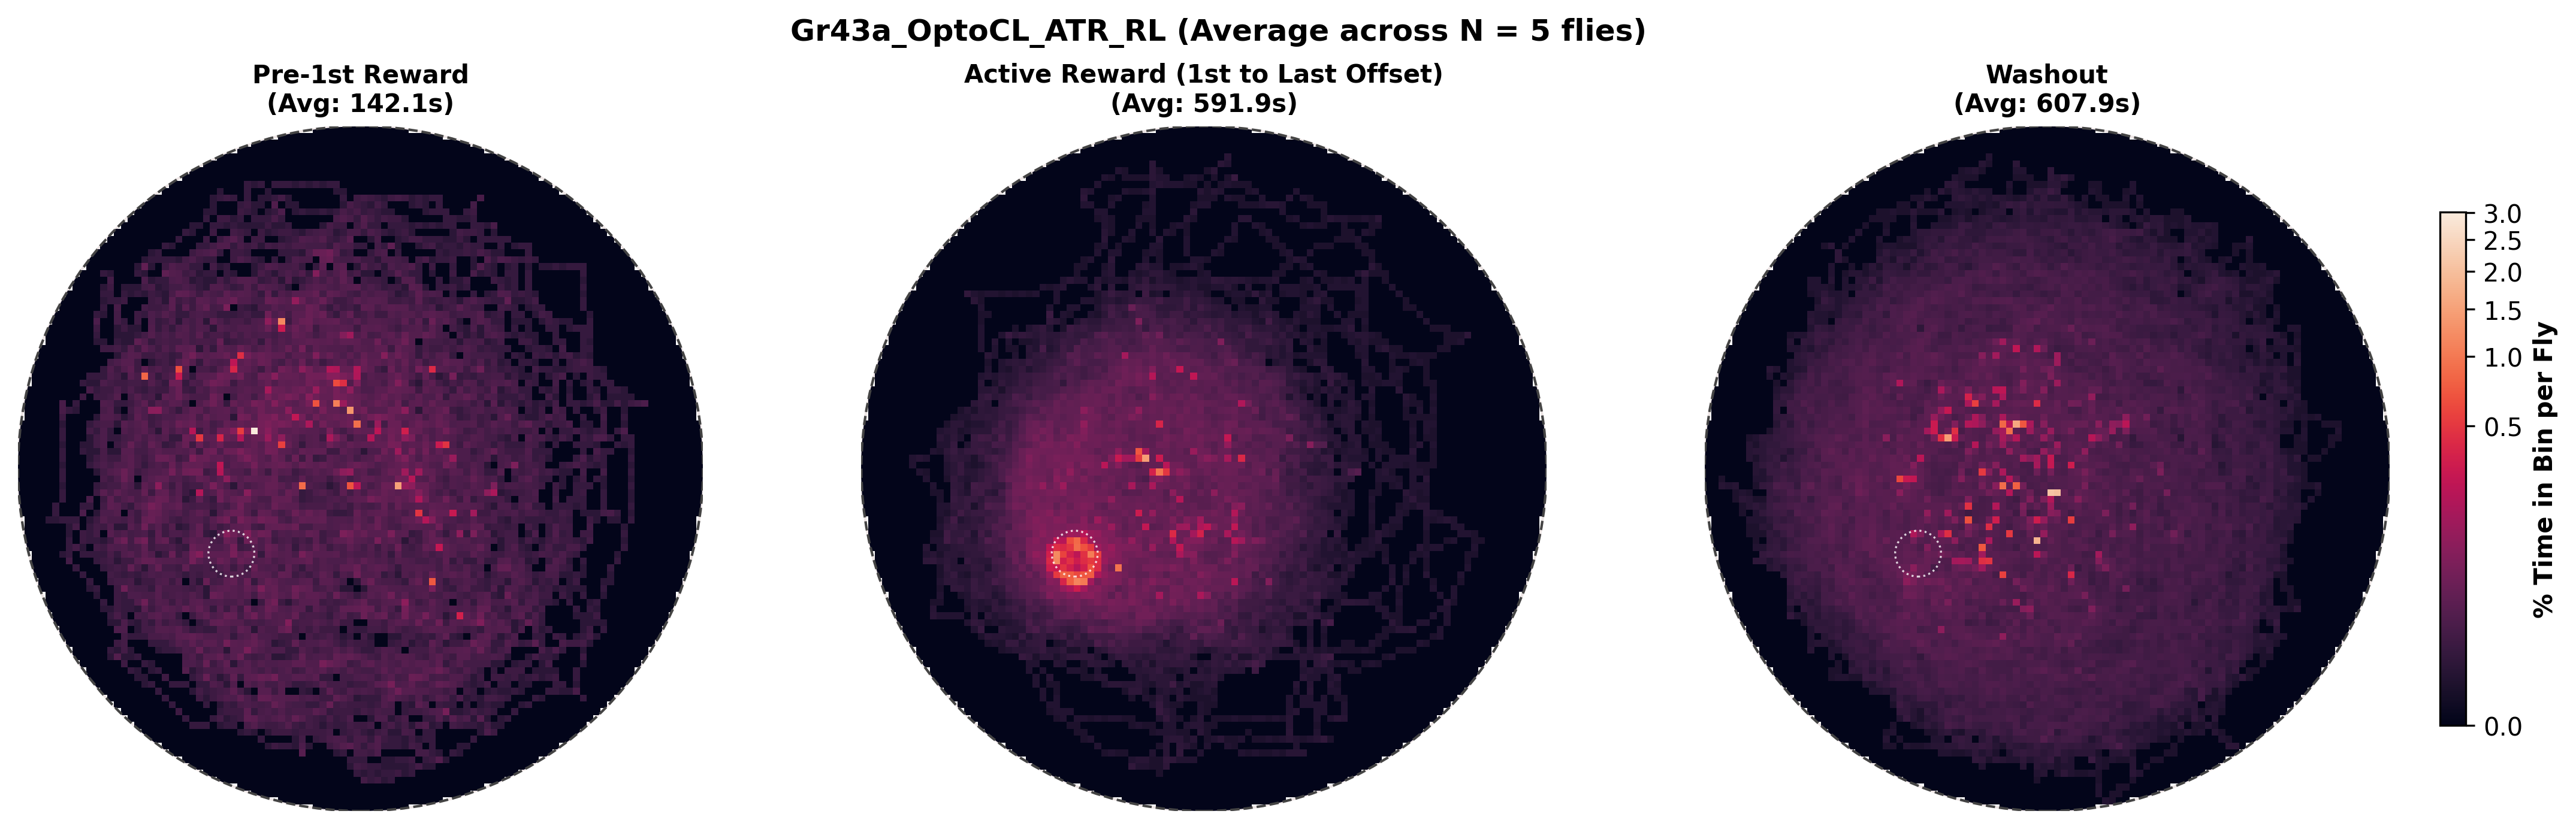

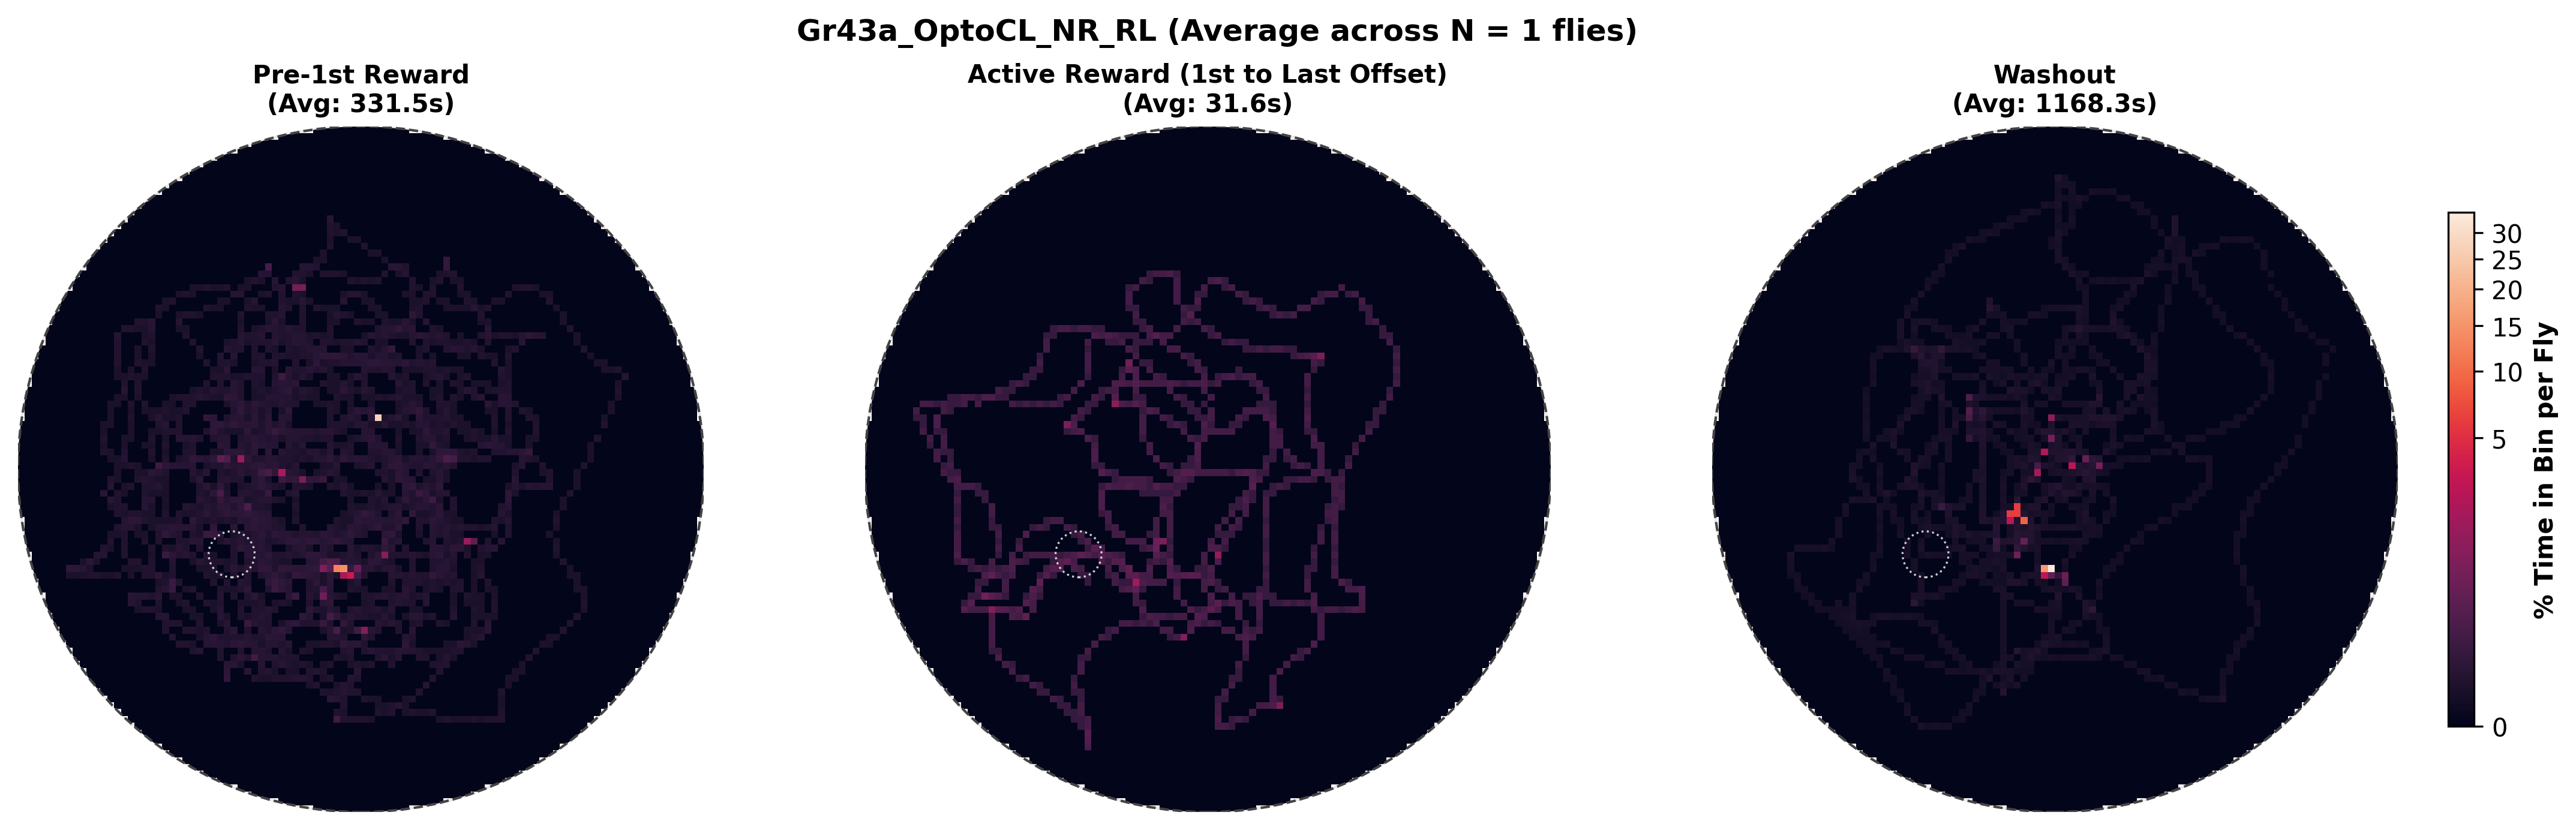

In [ ]:
df_Gr43a_ATR_CL_RL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="ATR", zone="RL")
df_Gr43a_NR_CL_RL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="NR", zone="RL")
dataset_Gr43a_ATR_CL_RL = load_experiment_dataset(df_Gr43a_ATR_CL_RL, fps=60.0)
dataset_Gr43a_NR_CL_RL = load_experiment_dataset(df_Gr43a_NR_CL_RL, fps=60.0)

print(len(df_Gr43a_ATR_CL_RL.index))


# 1.b) Dataset Average Cartesian Plot
fig1, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr43a_ATR_CL_RL, 
    dataset_name="Gr43a_OptoCL_ATR_RL")

# 1.b) Dataset Average Cartesian Plot
fig2, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr43a_NR_CL_RL, 
    dataset_name="Gr43a_OptoCL_NR_RL")

In [ ]:
# fig1.savefig("dataset_density_Gr43a_RL_ATR.png")
# fig2.savefig("dataset_density_Gr43a_RL_NR.png")

5


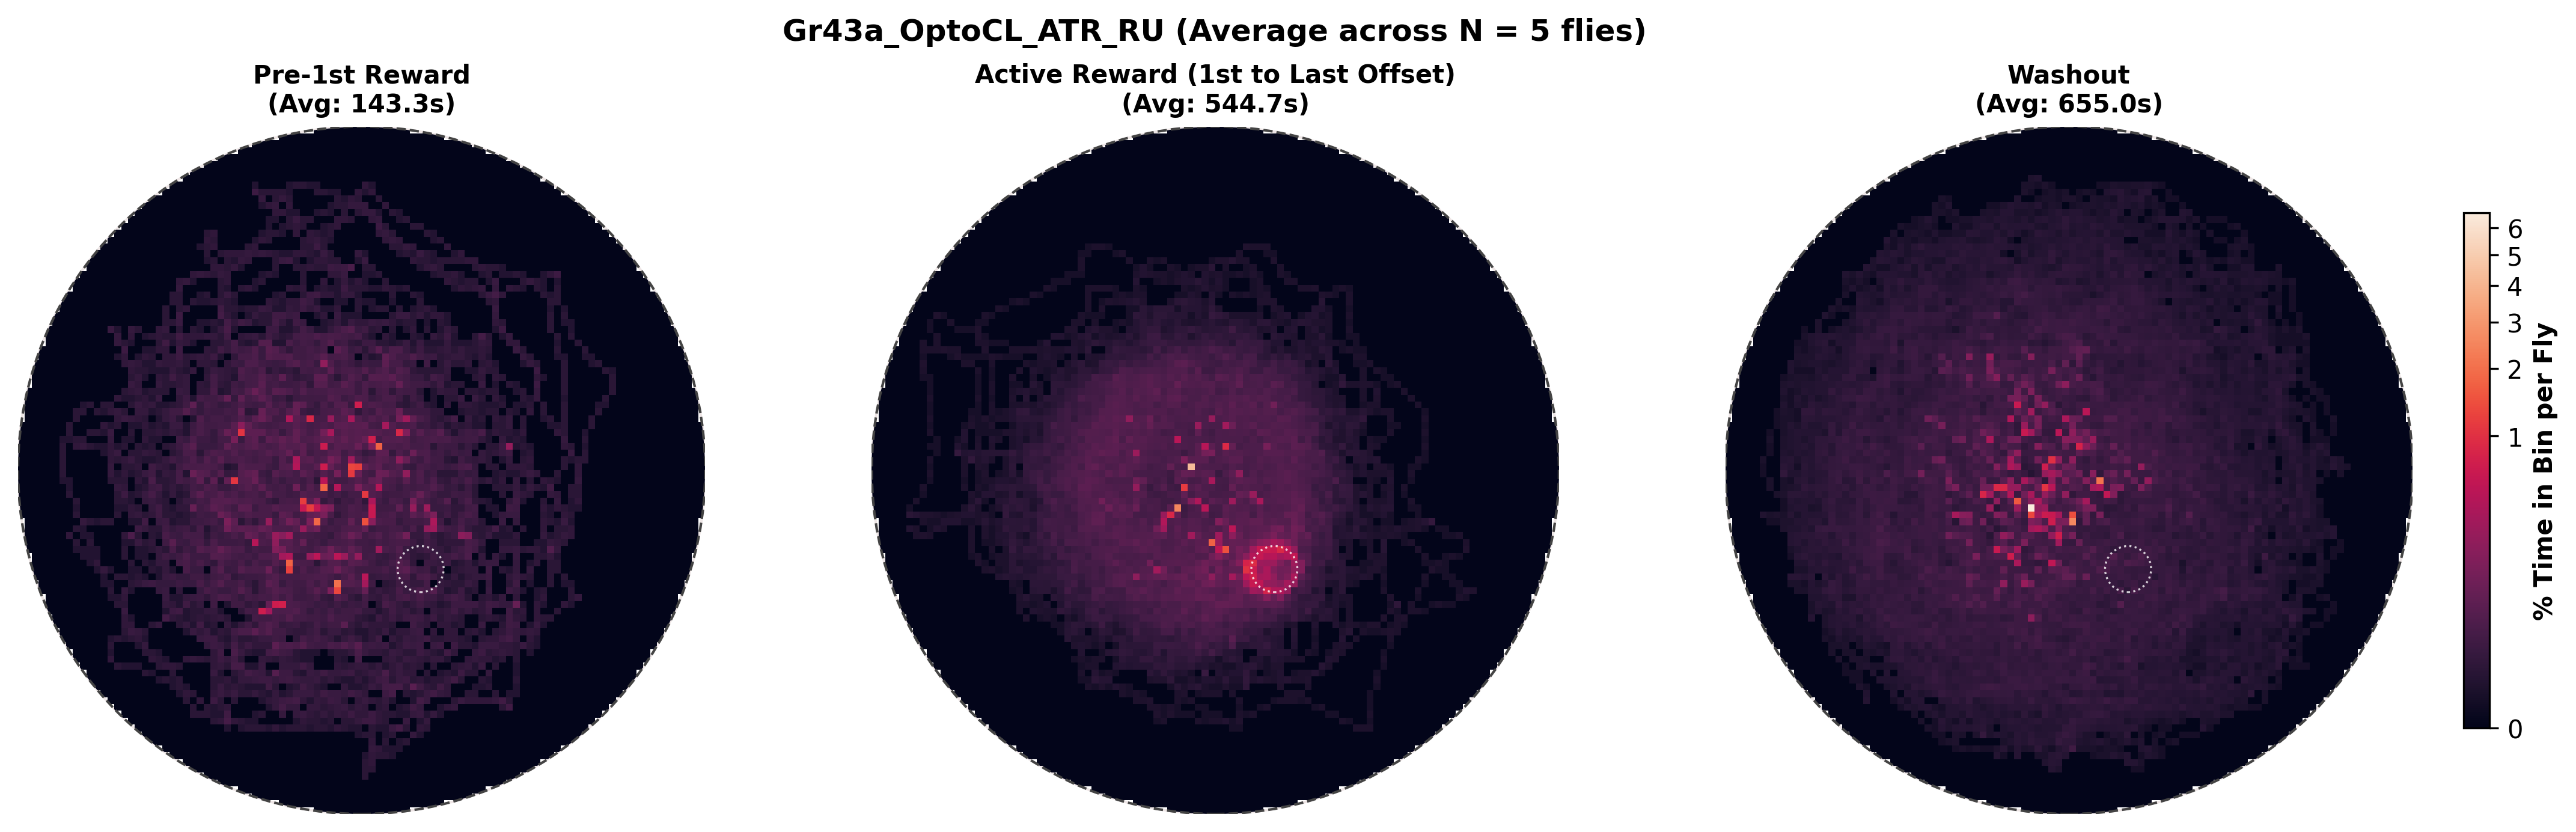

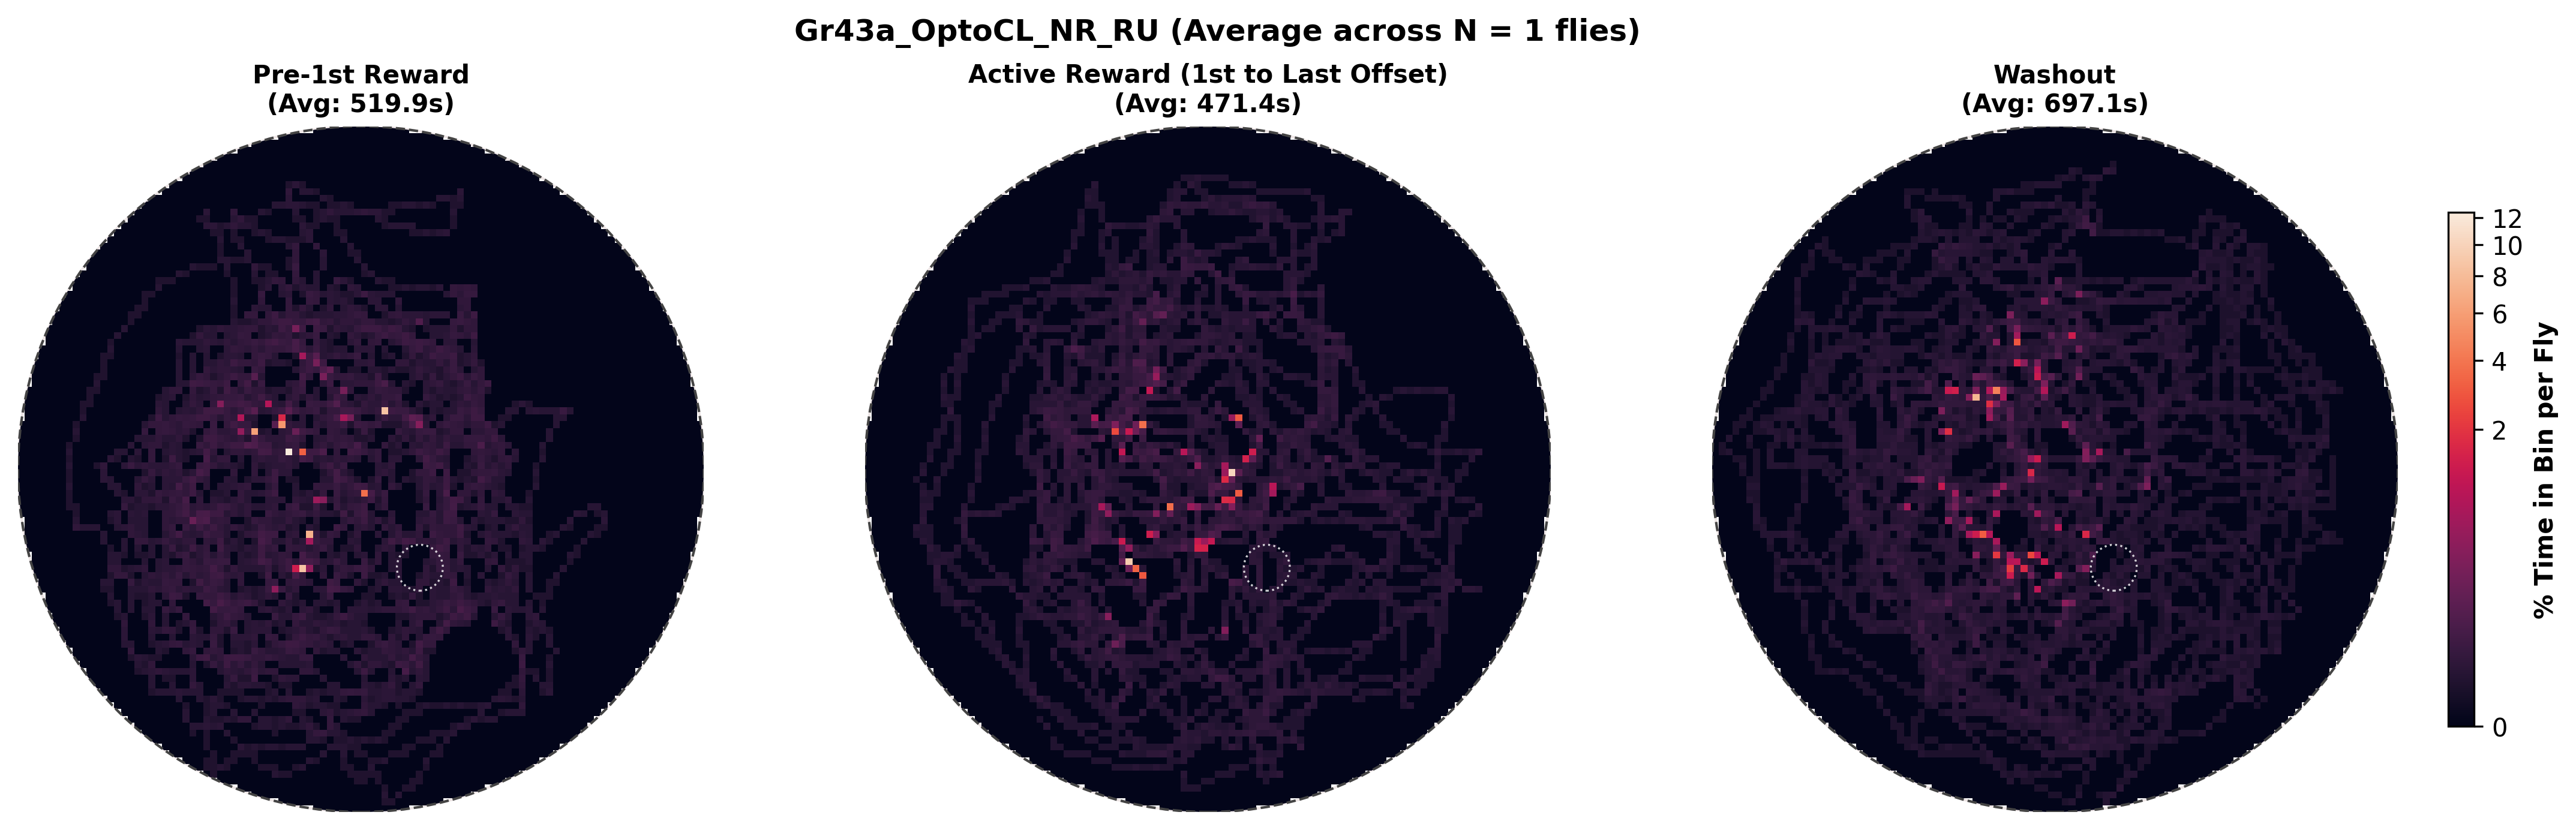

In [ ]:
df_Gr43a_ATR_CL_RU = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="ATR", zone="RU")
df_Gr43a_NR_CL_RU = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="NR", zone="RU")
dataset_Gr43a_ATR_CL_RU = load_experiment_dataset(df_Gr43a_ATR_CL_RU, fps=60.0)
dataset_Gr43a_NR_CL_RU = load_experiment_dataset(df_Gr43a_NR_CL_RU, fps=60.0)

print(len(df_Gr43a_ATR_CL_RU.index))


# 1.b) Dataset Average Cartesian Plot
fig1, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr43a_ATR_CL_RU, 
    dataset_name="Gr43a_OptoCL_ATR_RU")

# 1.b) Dataset Average Cartesian Plot
fig2, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr43a_NR_CL_RU, 
    dataset_name="Gr43a_OptoCL_NR_RU")

In [ ]:
# fig1.savefig("dataset_density_Gr43a_RU_ATR.png")
# fig2.savefig("dataset_density_Gr43a_RU_NR.png")

In [6]:
df_Gr43a_ATR_replay = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCLReplay", medium="ATR", zone="300")
dataset_Gr43a_ATR_replay = load_experiment_dataset(df_Gr43a_ATR_replay, fps=60.0)


print(len(df_Gr43a_ATR_replay.index))


# 1.b) Dataset Average Cartesian Plot
fig, ax = plot_dataset_average_cartesian_density(
    dataset=dataset_Gr43a_ATR_replay, 
    dataset_name="Gr43a_ATR_replay")

# fig.savefig("dataset_density_Gr43a_Replay_ATR.png")


12


NameError: name 'plot_dataset_average_cartesian_density' is not defined

In [ ]:
from behavior_fw.visualization.plot_density_washout import (
    plot_washout_chunks_cartesian,
)

for i in range(5):
# 1. Single Fly or Single Dataset (2-minute chunks)
    print(dataset_Gr43a_ATR_CL_LU[i]["n_rewards"])
    print(dataset_Gr43a_ATR_CL_LU[i]["first_reward_idx"])
    fig, axes = plot_washout_chunks_cartesian(
        dataset=[dataset_Gr43a_ATR_CL_LU[i]],  # Even if len(my_dataset) == 1
        dataset_name="Experimental Group",
        chunk_duration_sec=10.0,  # 2 minutes
        max_chunks=10,  # Plot first 5 chunks (0-10 mins of washout)
    )
    # fig.savefig(f"chunked_washout_Gr43a_ATR_CL_LU{i}.png")


In [ ]:
fig, axes = plot_single_experiment_psth(
    ds=dataset_Gr5a_NR_CL[7],
    metrics=["Vf_smooth", "Vr_abs"],
    window_sec=(-2.0, 3.0),
    stim_duration_sec=1.0,
    color="#C4A140",
    cmap="viridis"
)



In [ ]:

fig, axes = plot_condition_psth_summary(
    datasets=[dataset_Gr5a_ATR_CL],
    group_names=["Gr5a_ATR"],
    metrics=["Vf_smooth", "Vr_abs"],
    colors=["#F16237"],
    title="PSTH Velocity Summary"
)
plt.show()

In [ ]:

fig, axes = plot_condition_psth_summary(
    datasets=[dataset_Gr5a_ATR_CL,dataset_Gr43a_ATR_CL, dataset_Gr5a_NR_CL, dataset_Gr43a_NR_CL ],
    group_names=["Gr5a_ATR" ,"Gr43a_ATR", "Gr5a_NR", "Gr43a_NR"],
    metrics=["Vf_smooth", "Vr_abs"],
    colors=["#F16237", "#0E37BB", "#C4A140", "#37CCF1"],
    title="Mean velocities aligned to reward onset"
)
plt.show()

In [ ]:
# fig.savefig("summary_psth.png")

In [ ]:
from behavior_fw.analysis.detect_turns import detect_iri_saccades, detect_iri_saccade_magnitudes
from behavior_fw.utils.iris import extract_iri_rotational_velocity
from behavior_fw.visualization.plot_iri import plot_iri_rotational_velocity, plot_random_iri_samples

# 1. Extract variable-length IRIs from continuous track data
iris = extract_iri_rotational_velocity(dataset_Gr5a_NR_CL[6], min_iri_sec=3, fps=60.0)

# 2. Detect saccades and extract saccade_directions for each IRI
iris = detect_iri_saccades(iris, velocity_threshold=300.0, fps=60.0)

# # 3. Inspect a random sample of 5 IRIs visually
plot_random_iri_samples(iris, n_samples=5, seed=42)



In [8]:
dict_n_rewards = {}
dict_n_rewards["Gr5a_ATR_CL"] =[]
for ds in dataset_Gr5a_ATR_CL:
    dict_n_rewards["Gr5a_ATR_CL"].append(ds["n_rewards"])

dict_n_rewards["Gr5a_NR_CL"] =[]
for ds in dataset_Gr5a_NR_CL:
    dict_n_rewards["Gr5a_NR_CL"].append(ds["n_rewards"])

dict_n_rewards["Gr43a_ATR_CL"] =[]
for ds in dataset_Gr43a_ATR_CL:
    dict_n_rewards["Gr43a_ATR_CL"].append(ds["n_rewards"])

dict_n_rewards["Gr43a_NR_CL"] =[]
for ds in dataset_Gr43a_NR_CL:
    dict_n_rewards["Gr43a_NR_CL"].append(ds["n_rewards"])

dict_n_rewards["Gr43a_ATR_replay"] =[]
for ds in dataset_Gr43a_ATR_replay:
    dict_n_rewards["Gr43a_ATR_replay"].append(ds["n_rewards"])



In [9]:
import seaborn as sns

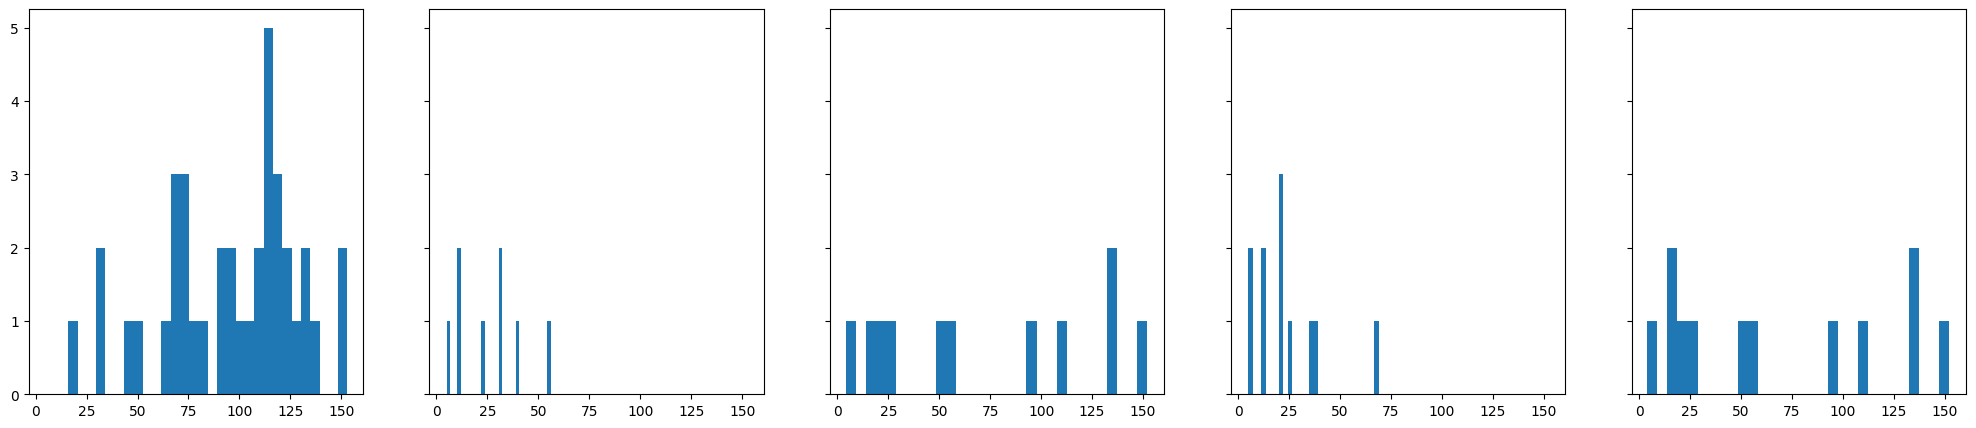

In [10]:
fig, axes = plt.subplots(1,5, figsize=(25,5), sharex=True, sharey=True)
for i, key in enumerate(dict_n_rewards.keys()):
    # print(key, dict_n_rewards[key][0])
    axes[i].hist(dict_n_rewards[key], bins=30)
    

In [135]:
dict_n_rewards = {}

dict_n_rewards["Gr43a_ATR_CL"] =[]
for ds in dataset_Gr43a_ATR_CL:
    dict_n_rewards["Gr43a_ATR_CL"].append(ds["n_rewards"])

dict_n_rewards["Gr43a_ATR_CL_LL"] =[]
for ds in dataset_Gr43a_ATR_CL_LL:
    dict_n_rewards["Gr43a_ATR_CL_LL"].append(ds["n_rewards"])

dict_n_rewards["Gr43a_ATR_CL_LU"] =[]
for ds in dataset_Gr43a_ATR_CL_LU:
    dict_n_rewards["Gr43a_ATR_CL_LU"].append(ds["n_rewards"])

dict_n_rewards["Gr43a_ATR_CL_RU"] =[]
for ds in dataset_Gr43a_ATR_CL_RU:
    dict_n_rewards["Gr43a_ATR_CL_RU"].append(ds["n_rewards"])

dict_n_rewards["Gr43a_ATR_CL_RL"] =[]
for ds in dataset_Gr43a_ATR_CL_RL:
    dict_n_rewards["Gr43a_ATR_CL_RL"].append(ds["n_rewards"])

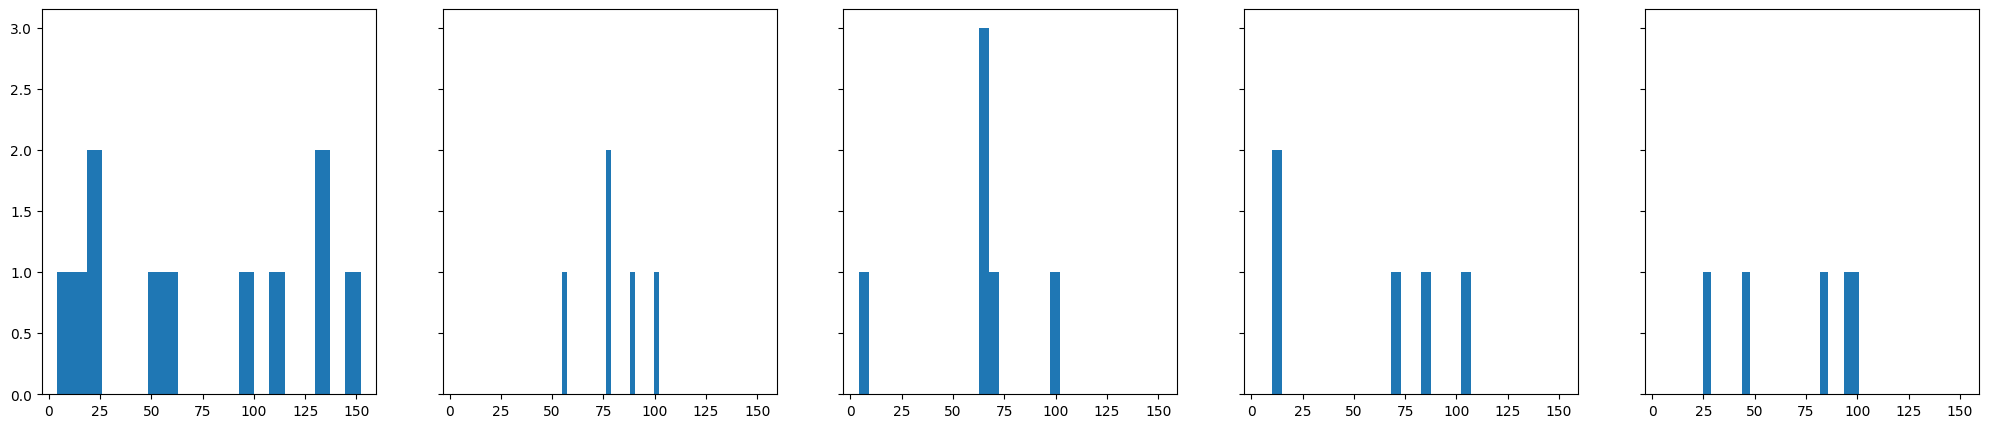

In [137]:
fig, axes = plt.subplots(1,5, figsize=(25,5), sharex=True, sharey=True)
for i, key in enumerate(dict_n_rewards.keys()):
    # print(key, dict_n_rewards[key][0])
    axes[i].hist(dict_n_rewards[key], bins=20)
    

In [ ]:

# 2. Polar Plot for 2-minute Washout Chunks
fig_polar, axes_polar = plot_washout_chunks_polar(
    dataset=my_dataset,
    chunk_duration_sec=120.0,
    max_chunks=5,
)

# 3. Compare Washout Decay Across Multiple Conditions
fig_comp, axes_comp = plot_compare_washout_chunks_cartesian(
    datasets=[control_dataset, exp_dataset],
    group_names=["Control", "Experimental"],
    chunk_duration_sec=120.0,
    num_chunks_to_plot=4,
)

In [ ]:

# 1.c) Cartesian Comparison Across Conditions
fig, ax = plot_compare_conditions_cartesian(
    datasets=[dataset_Gr43a_ATR_CL, dataset_Gr5a_ATR_CL, dataset_Gr43a_NR_CL, dataset_Gr5a_NR_CL],
    group_names=["Gr43a_ATR", "Gr5a_ATR", "Gr43a_NR", "Gr5a_NR"],
    normalize_across_datasets=True  # Toggle ON/OFF as needed
)


In [ ]:

# 2.a) Single Polar Experiment Plot
fig, ax = plot_single_experiment_polar_density(
    dataset=dataset_Gr43a_ATR_CL, 
    exp_idx=0, 
    dataset_name="Gr43a_OptoCL_ATR"
)

# 2.b) Dataset Average Polar Plot
fig, ax = plot_dataset_average_polar_density(
    dataset=dataset_Gr43a_ATR_CL, 
    dataset_name="Gr43a_OptoCL_ATR"
)

# 2.c) Polar Comparison Across Conditions
fig, ax = plot_compare_conditions_polar(
    datasets=[dataset_Gr43a_ATR_CL, dataset_Gr5a_ATR_CL],
    group_names=["Gr43a_ATR", "Gr5a_ATR"],
    normalize_across_datasets=False  # Toggle ON/OFF as needed
)

In [123]:
import numpy as np
import pandas as pd


def analyze_spatial_memory_metrics(
    exp_list: list, fps: float = 60.0
) -> pd.DataFrame:
    records = []

    for exp in exp_list:
        fly_id = exp.get("uid", exp.get("folder_path", "fly"))
        df_track = exp.get("df_track", None)
        zone_x = exp.get("zone_X", 0.0)  # Reward X center
        zone_y = exp.get("zone_Y", 0.0)  # Reward Y center

        if df_track is None or "LEDstate" not in df_track.columns:
            continue

        led_states = df_track["LEDstate"].values
        led_diff = np.diff(led_states, prepend=0)

        offsets = np.where(led_diff == -1)[0]
        onsets = np.where(led_diff == 1)[0]

        for iri_idx, off_idx in enumerate(offsets):
            next_on = onsets[onsets > off_idx]
            if len(next_on) == 0:
                continue
            next_on_idx = next_on[0]

            # Slicing IRI trajectory
            x = df_track["X"].iloc[off_idx:next_on_idx].values
            y = df_track["Y"].iloc[off_idx:next_on_idx].values
            ori = df_track["ori_angle_cal"].iloc[off_idx:next_on_idx].values

            if len(x) < int(2.0 * fps):
                continue

            # 1. Radial Distance to Reward Origin over time
            dist_to_origin = np.sqrt((x - zone_x) ** 2 + (y - zone_y) ** 2)

            # 2. Angle pointing toward Reward Center relative to Fly's Heading
            angle_to_origin = np.arctan2(zone_y - y, zone_x - x)  # Radians
            heading_rad = np.deg2rad(ori)

            # Angular difference (-pi to +pi)
            angle_diff = np.arctan2(
                np.sin(angle_to_origin - heading_rad),
                np.cos(angle_to_origin - heading_rad),
            )

            # 3. Spatial Return Metric: Count crossings back into reward zone (e.g. < 5mm)
            returns_to_center = np.sum(
                (dist_to_origin[:-1] < 5.0) & (dist_to_origin[1:] >= 5.0)
            )

            records.append({
                "fly_id": fly_id,
                "iri_idx": iri_idx,
                "mean_dist_to_origin": np.mean(dist_to_origin),
                "max_dist_to_origin": np.max(dist_to_origin),
                "returns_to_center": returns_to_center,
                "target_heading_bias": np.mean(
                    np.abs(angle_diff)
                ),  # Lower = more targeted toward origin
            })

    return pd.DataFrame(records)

mean_dist_to_origin       | ATR mean: 7.52 | NR mean: 16.63 | p-val: 2.3362e-60
max_dist_to_origin        | ATR mean: 13.29 | NR mean: 29.09 | p-val: 3.6221e-53
returns_to_center         | ATR mean: 1.58 | NR mean: 0.78 | p-val: 2.0464e-05
target_heading_bias       | ATR mean: 1.62 | NR mean: 1.51 | p-val: 4.9197e-02


/tmp/ipykernel_6097/3581492791.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_6097/3581492791.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_6097/3581492791.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_6097/3581492791.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


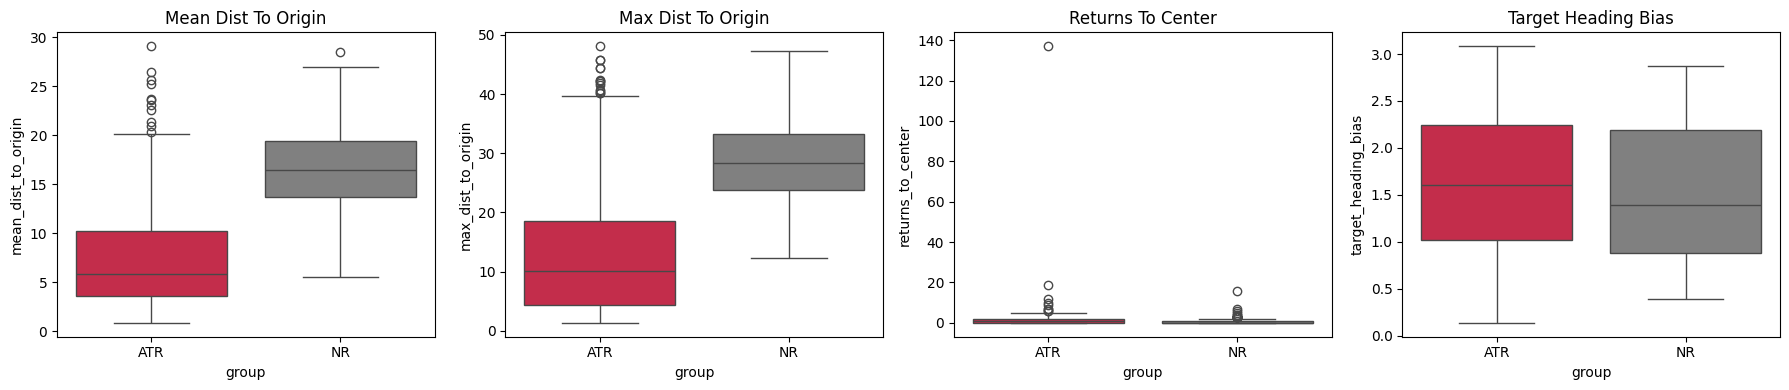

In [124]:
df_atr =  analyze_spatial_memory_metrics(dataset_Gr43a_ATR_CL)
df_nr =  analyze_spatial_memory_metrics(dataset_Gr43a_NR_CL)

from scipy import stats

# 1. Compute summary stats per group
df_atr["group"] = "ATR"
df_nr["group"] = "NR"
df_combined = pd.concat([df_atr, df_nr], ignore_index=True)

# 2. Key Statistical Tests
metrics = [
    "mean_dist_to_origin",
    "max_dist_to_origin",
    "returns_to_center",
    "target_heading_bias",
]

for metric in metrics:
    atr_vals = df_combined[df_combined["group"] == "ATR"][metric].dropna()
    nr_vals = df_combined[df_combined["group"] == "NR"][metric].dropna()

    # Mann-Whitney U test (non-parametric comparison)
    stat, p_val = stats.mannwhitneyu(
        atr_vals, nr_vals, alternative="two-sided"
    )
    print(
        f"{metric:<25} | ATR mean: {atr_vals.mean():.2f} | NR mean: {nr_vals.mean():.2f} | p-val: {p_val:.4e}"
    )

# 3. Visualization
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, metric in enumerate(metrics):
    sns.boxplot(
        data=df_combined,
        x="group",
        y=metric,
        ax=axes[i],
        palette=["crimson", "gray"],
    )
    axes[i].set_title(metric.replace("_", " ").title())
plt.tight_layout()
plt.show()

In [125]:
def extract_radial_trajectories(
    exp_list: list, fps: float = 60.0, max_sec: float = 10.0
):
    """Extracts frame-by-frame distance to origin R(t) over time across IRIs."""
    max_frames = int(max_sec * fps)
    r_matrix = []

    for exp in exp_list:
        df_track = exp.get("df_track", None)
        zone_x, zone_y = exp.get("zone_X", 0.0), exp.get("zone_Y", 0.0)

        if df_track is None or "LEDstate" not in df_track.columns:
            continue

        led_states = df_track["LEDstate"].values
        led_diff = np.diff(led_states, prepend=0)
        offsets = np.where(led_diff == -1)[0]
        onsets = np.where(led_diff == 1)[0]

        for off_idx in offsets:
            next_on = onsets[onsets > off_idx]
            if len(next_on) == 0:
                continue
            next_on_idx = next_on[0]

            # Exclude visual startle window (first 1.0 sec)
            start = off_idx + int(0 * fps)
            if next_on_idx - start < int(2.0 * fps):
                continue

            x = df_track["X"].iloc[start:next_on_idx].values
            y = df_track["Y"].iloc[start:next_on_idx].values
            r = np.sqrt((x - zone_x) ** 2 + (y - zone_y) ** 2)

            if len(r) >= max_frames:
                r_matrix.append(r[:max_frames])

    return np.array(r_matrix)


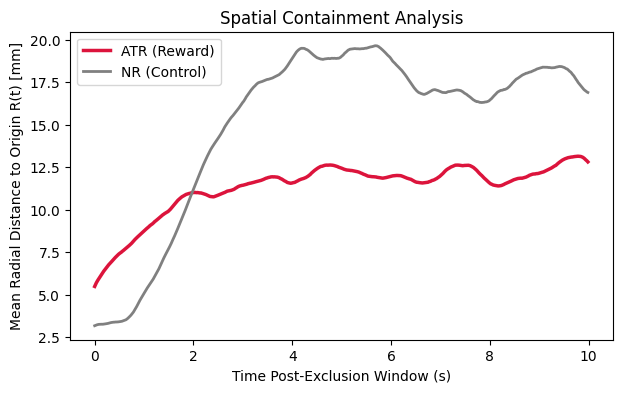

In [126]:


# Plot mean R(t) over time
r_atr = extract_radial_trajectories(dataset_Gr43a_ATR_CL)
r_nr = extract_radial_trajectories(dataset_Gr43a_ATR_CL_RL)

time_axis = np.arange(r_atr.shape[1]) / 60.0

plt.figure(figsize=(7, 4))
plt.plot(
    time_axis,
    np.mean(r_atr, axis=0),
    color="crimson",
    lw=2.5,
    label="ATR (Reward)",
)
plt.plot(time_axis, np.mean(r_nr, axis=0), color="gray", lw=2, label="NR (Control)")
plt.xlabel("Time Post-Exclusion Window (s)")
plt.ylabel("Mean Radial Distance to Origin R(t) [mm]")
plt.title("Spatial Containment Analysis")
plt.legend()
plt.show()

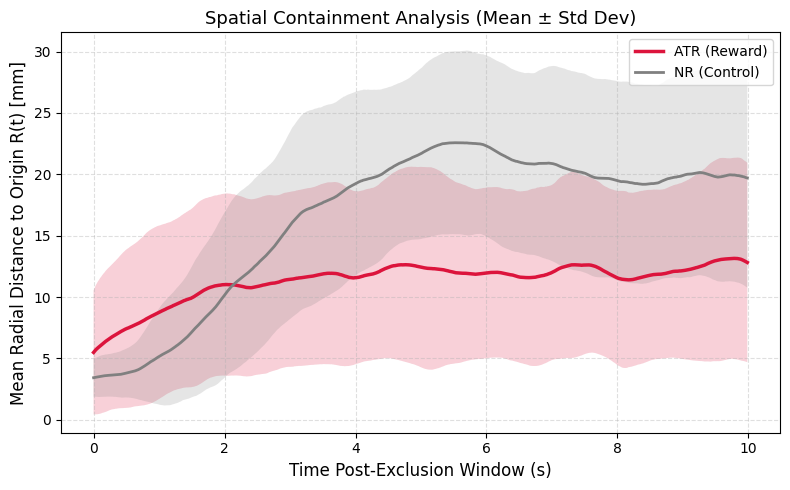

In [127]:


# Plot mean R(t) over time
r_atr = extract_radial_trajectories(dataset_Gr43a_ATR_CL)
r_nr = extract_radial_trajectories(dataset_Gr43a_ATR_CL_LL)


from scipy import stats

# 1. Compute Mean and Standard Deviation (or Standard Error)
mean_atr = np.mean(r_atr, axis=0)
std_atr = np.std(r_atr, axis=0)
# Optional: Use Standard Error of the Mean (SEM) for cleaner error bands:
# sem_atr = stats.sem(r_atr, axis=0)

mean_nr = np.mean(r_nr, axis=0)
std_nr = np.std(r_nr, axis=0)

time_axis = np.arange(r_atr.shape[1]) / 60.0  # Time in seconds (60 Hz)

# 2. Plotting with Shaded Standard Deviation Bands
plt.figure(figsize=(8, 5))

# ATR (Reward Group)
plt.plot(time_axis, mean_atr, color="crimson", lw=2.5, label="ATR (Reward)")
plt.fill_between(
    time_axis,
    mean_atr - std_atr,
    mean_atr + std_atr,
    color="crimson",
    alpha=0.2,  # Transparency
    edgecolor="none",
)

# NR (Control Group)
plt.plot(time_axis, mean_nr, color="gray", lw=2, label="NR (Control)")
plt.fill_between(
    time_axis,
    mean_nr - std_nr,
    mean_nr + std_nr,
    color="gray",
    alpha=0.2,
    edgecolor="none",
)

# Formatting
plt.xlabel("Time Post-Exclusion Window (s)", fontsize=12)
plt.ylabel("Mean Radial Distance to Origin R(t) [mm]", fontsize=12)
plt.title("Spatial Containment Analysis (Mean ± Std Dev)", fontsize=13)
plt.legend(loc="upper right", frameon=True)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

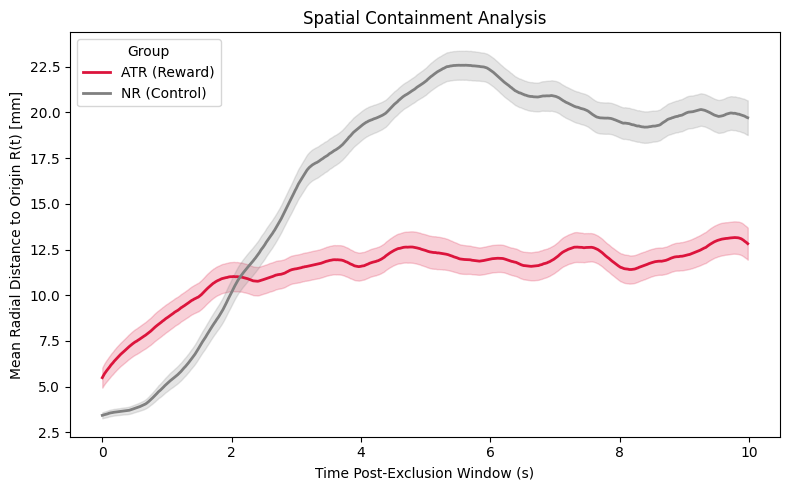

In [128]:
import pandas as pd
import seaborn as sns


# 1. Convert arrays (N_trials, N_frames) to long-format DataFrame
def matrix_to_long_df(r_matrix, group_name, fps=60.0):
    n_trials, n_frames = r_matrix.shape
    time = np.tile(np.arange(n_frames) / fps, n_trials)
    distance = r_matrix.flatten()
    trial_id = np.repeat(np.arange(n_trials), n_frames)

    return pd.DataFrame({
        "Time (s)": time,
        "Distance (mm)": distance,
        "Group": group_name,
        "Trial": trial_id,
    })


df_atr_long = matrix_to_long_df(r_atr, "ATR (Reward)")
df_nr_long = matrix_to_long_df(r_nr, "NR (Control)")
df_plot = pd.concat([df_atr_long, df_nr_long], ignore_index=True)

# 2. Plot with errorbar='sd' (Standard Deviation)
plt.figure(figsize=(8, 5))
sns.lineplot(
    data=df_plot,
    x="Time (s)",
    y="Distance (mm)",
    hue="Group",
    palette=["crimson", "gray"],
    errorbar="se",  # Use 'sd' for Std Dev, or 'se' for Standard Error
    linewidth=2,
)

plt.title("Spatial Containment Analysis")
plt.xlabel("Time Post-Exclusion Window (s)")
plt.ylabel("Mean Radial Distance to Origin R(t) [mm]")
plt.tight_layout()
plt.show()

In [129]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def compute_zone_and_reward_metrics_dict(exp_dict, zone_r=5.0, epsilon=1.0, fps=60.0):
    """
    Computes zone metrics for a single experiment dictionary.
    Keys expected: 'zone_X', 'zone_Y', 'df_track'
    """
    zone_x = exp_dict['zone_X']
    zone_y = exp_dict['zone_Y']
    zone_r = exp_dict['zone_r']
    df = exp_dict['df_track']
    
    # Auto-detect column name for X and Y coordinates
    x_col = 'X' if 'X' in df.columns else 'X_cal'
    y_col = 'Y' if 'Y' in df.columns else 'Y_cal'
    
    dist = np.hypot(df[x_col] - zone_x, df[y_col] - zone_y)
    in_zone_core = dist <= zone_r
    out_zone_padded = dist > (zone_r + epsilon)
    
    # Hysteresis state machine to track discrete entries & exits
    state = False
    entry_indices, exit_indices = [], []
    for i in range(len(df)):
        if not state and in_zone_core[i]:
            state = True
            entry_indices.append(i)
        elif state and out_zone_padded[i]:
            state = False
            exit_indices.append(i)
            
    # Detect reward onsets (LEDstate 0 -> 1 transitions)
    led_state = df['LEDstate'].values
    reward_onset_indices = np.where((led_state[:-1] == 0) & (led_state[1:] == 1))[0] + 1
    
    # Differential step lengths (mm) and time vector (s)
    step_lengths = np.hypot(df[x_col].diff(), df[y_col].diff()).fillna(0).values
    time_sec = np.arange(len(df)) / fps
    
    reward_records = []
    for k in range(len(reward_onset_indices) - 1):
        idx_start = reward_onset_indices[k]
        idx_end = reward_onset_indices[k+1]
        
        dist_mm = np.sum(step_lengths[idx_start:idx_end])
        dt_sec = time_sec[idx_end] - time_sec[idx_start]
        
        reward_records.append({
            'reward_num': k + 1,
            'time_onset_s': time_sec[idx_start],
            'inter_reward_dist_mm': dist_mm,
            'inter_reward_time_s': dt_sec
        })
        
    df_rewards = pd.DataFrame(reward_records)
    
    summary = {
        'n_entries': len(entry_indices),
        'n_exits': len(exit_indices),
        'n_rewards': len(reward_onset_indices),
        'entry_indices': entry_indices,
        'exit_indices': exit_indices,
        'reward_onset_indices': reward_onset_indices
    }
    
    return summary, df_rewards


def compute_active_occupancy_dict(exp_dict, zone_r=5.0, v_thresh=1.5):
    """
    Computes occupancy in Activation Zone vs. 3 Radial-Matched Control Zones
    from an experiment dictionary, discounting freezing bouts (Vf_smooth <= v_thresh).
    """
    zone_x = exp_dict['zone_X']
    zone_y = exp_dict['zone_Y']
    zone_r = exp_dict['zone_r']
    df = exp_dict['df_track']
    
    x_col = 'X' if 'X' in df.columns else 'X_cal'
    y_col = 'Y' if 'Y' in df.columns else 'Y_cal'
    
    # 3 Radial-matched control zone centers rotated by 90, 180, 270 degrees
    r_center = np.hypot(zone_x, zone_y)
    angle_act = np.arctan2(zone_y, zone_x)
    
    control_coords = []
    for deg in [90, 180, 270]:
        ang = angle_act + np.radians(deg)
        control_coords.append((r_center * np.cos(ang), r_center * np.sin(ang)))
        
    # Active movement mask
    v_col = 'Vf_smooth' if 'Vf_smooth' in df.columns else 'Vf'
    active_mask = df[v_col] > v_thresh if v_col in df.columns else np.ones(len(df), dtype=bool)
    
    # Count active frames in activation zone
    dist_act = np.hypot(df[x_col] - zone_x, df[y_col] - zone_y)
    active_frames_act = np.sum((dist_act <= zone_r) & active_mask)
    
    # Count active frames in control zones
    ctrl_active_counts = []
    for cx, cy in control_coords:
        dist_ctrl = np.hypot(df[x_col] - cx, df[y_col] - cy)
        ctrl_active_counts.append(np.sum((dist_ctrl <= zone_r) & active_mask))
        
    avg_active_frames_ctrl = np.mean(ctrl_active_counts)
    
    # Occupancy index (-1.0 to +1.0)
    denom = active_frames_act + avg_active_frames_ctrl
    occ_idx = (active_frames_act - avg_active_frames_ctrl) / denom if denom > 0 else 0.0
    
    return {
        'active_frames_act': active_frames_act,
        'active_frames_ctrl_avg': avg_active_frames_ctrl,
        'active_occupancy_index': occ_idx
    }

In [32]:
# --- 1. PROCESS ALL EXPERIMENTS IN LISTS ---
def analyze_dataset_list(list_of_exp_dicts, group_label="Experimental"):
    results = []
    all_rewards = []
    
    for idx, exp in enumerate(list_of_exp_dicts):
        summary, df_rew = compute_zone_and_reward_metrics_dict(exp)
        occ = compute_active_occupancy_dict(exp)
        
        # Tag dataset metadata
        df_rew['fly_id'] = idx
        df_rew['group'] = group_label
        all_rewards.append(df_rew)
        
        results.append({
            'fly_id': idx,
            'group': group_label,
            'n_entries': summary['n_entries'],
            'n_exits': summary['n_exits'],
            'n_rewards': summary['n_rewards'],
            'active_occupancy_index': occ['active_occupancy_index']
        })
        
    df_summary = pd.DataFrame(results)
    df_all_rewards = pd.concat(all_rewards, ignore_index=True) if all_rewards else pd.DataFrame()
    return df_summary, df_all_rewards


In [55]:

# Example Usage:
df_exp_summary, df_exp_rewards = analyze_dataset_list(dataset_Gr43a_ATR_CL_LL, group_label="Gr43a")
df_ctrl_summary, df_ctrl_rewards = analyze_dataset_list(dataset_Gr43a_ATR_CL_RU, group_label="Control")
df_combined_summary = pd.concat([df_exp_summary, df_ctrl_summary], ignore_index=True)

/tmp/ipykernel_6097/492131156.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_combined_summary, x='group', y='active_occupancy_index', ax=axes[1], palette=['crimson', 'gray'])


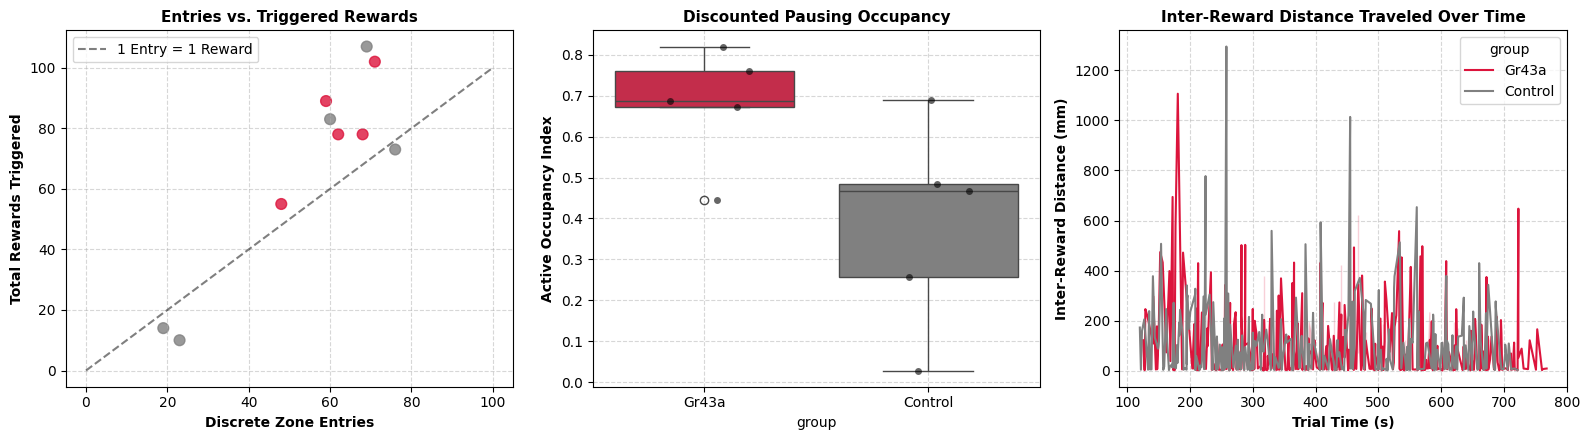

In [56]:
# --- 2. PLOT GROUP COMPARISONS & TEMPORAL DYNAMICS ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot 1: Discrete Entries vs Rewards
# (Demonstrates entry lockout due to refractory periods)
axes[0].scatter(df_combined_summary['n_entries'], df_combined_summary['n_rewards'], 
                 c=df_combined_summary['group'].map({'Gr43a': 'crimson', 'Control': 'gray'}), alpha=0.8, s=60)
axes[0].plot([0, 100], [0, 100], 'k--', alpha=0.5, label='1 Entry = 1 Reward')
axes[0].set_xlabel('Discrete Zone Entries', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Total Rewards Triggered', fontsize=10, fontweight='bold')
axes[0].set_title('Entries vs. Triggered Rewards', fontsize=11, fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Active Occupancy Index Comparison
import seaborn as sns
sns.boxplot(data=df_combined_summary, x='group', y='active_occupancy_index', ax=axes[1], palette=['crimson', 'gray'])
sns.stripplot(data=df_combined_summary, x='group', y='active_occupancy_index', ax=axes[1], color='black', alpha=0.6, jitter=0.2)
axes[1].set_ylabel('Active Occupancy Index', fontsize=10, fontweight='bold')
axes[1].set_title('Discounted Pausing Occupancy', fontsize=11, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Plot 3: Inter-Reward Distance Evolution over Time
sns.lineplot(data=pd.concat([df_exp_rewards, df_ctrl_rewards]), x='time_onset_s', y='inter_reward_dist_mm', 
             hue='group', ax=axes[2], palette=['crimson', 'gray'])
axes[2].set_xlabel('Trial Time (s)', fontsize=10, fontweight='bold')
axes[2].set_ylabel('Inter-Reward Distance (mm)', fontsize=10, fontweight='bold')
axes[2].set_title('Inter-Reward Distance Traveled Over Time', fontsize=11, fontweight='bold')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def compute_tactive_per_zone_dict(exp_dict, zone_r=5.0, v_thresh=1.5, fps=60.0):
    """
    Calculates active time (Tactive in seconds) for Activation Zone and 3 Control Zones.
    Window restricted to: First Reward Onset -> Last Reward Offset.
    """
    zone_x = exp_dict['zone_X']
    zone_y = exp_dict['zone_Y']
    zone_r = exp_dict['zone_r']
    df = exp_dict['df_track']
    
    x_col = 'X' if 'X' in df.columns else 'X_cal'
    y_col = 'Y' if 'Y' in df.columns else 'Y_cal'
    v_col = 'Vf_smooth' if 'Vf_smooth' in df.columns else 'Vf'
    
    # 1. Isolate time window between first reward onset and last reward offset
    led_state = df['LEDstate'].values
    reward_onsets = np.where((led_state[:-1] == 0) & (led_state[1:] == 1))[0] + 1
    reward_offsets = np.where((led_state[:-1] == 1) & (led_state[1:] == 0))[0] + 1
    
    if len(reward_onsets) == 0:
        return None  # No rewards triggered in this experiment
        
    start_idx = reward_onsets[0]
    end_idx = reward_offsets[-1] if len(reward_offsets) > 0 else len(df) - 1
    
    # Slice tracking dataframe to reward window
    sub_df = df.iloc[start_idx:end_idx + 1].copy()
    
    # 2. Derive 3 radial-matched control centers (rotated 90°, 180°, 270°)
    r_center = np.hypot(zone_x, zone_y)
    angle_act = np.arctan2(zone_y, zone_x)
    
    control_coords = []
    for deg in [90, 180, 270]:
        ang = angle_act + np.radians(deg)
        control_coords.append((r_center * np.cos(ang), r_center * np.sin(ang)))
        
    # Active locomotion mask (filters out Gr5a/Gr43a-induced pausing)
    active_mask = sub_df[v_col] > v_thresh if v_col in sub_df.columns else np.ones(len(sub_df), dtype=bool)
    
    # 3. Compute active residence time in seconds
    dist_act = np.hypot(sub_df[x_col] - zone_x, sub_df[y_col] - zone_y)
    t_act_zone = np.sum((dist_act <= zone_r) & active_mask) / fps
    
    t_ctrl_zones = []
    for cx, cy in control_coords:
        dist_ctrl = np.hypot(sub_df[x_col] - cx, sub_df[y_col] - cy)
        t_ctrl_zones.append(np.sum((dist_ctrl <= zone_r) & active_mask) / fps)
        
    return {
        'Activation Zone': t_act_zone,
        'Control Zone 1 (90°)': t_ctrl_zones[0],
        'Control Zone 2 (180°)': t_ctrl_zones[1],
        'Control Zone 3 (270°)': t_ctrl_zones[2],
        'Control Avg': np.mean(t_ctrl_zones),
        'Window_Duration_s': (end_idx - start_idx) / fps
    }


def analyze_tactive_dataset_list(list_of_exp_dicts, group_label="Experimental"):
    """
    Iterates through a dataset list and aggregates Tactive per zone into long-form DataFrames.
    """
    records = []
    for idx, exp in enumerate(list_of_exp_dicts):
        res = compute_tactive_per_zone_dict(exp)
        if res is None:
            continue
            
        for zone_name in ['Activation Zone', 'Control Zone 1 (90°)', 'Control Zone 2 (180°)', 'Control Zone 3 (270°)']:
            records.append({
                'fly_id': idx,
                'group': group_label,
                'Zone': zone_name,
                'Is_Activation_Zone': (zone_name == 'Activation Zone'),
                'T_active_s': res[zone_name],
                'Window_Duration_s': res['Window_Duration_s']
            })
            
    return pd.DataFrame(records)

/tmp/ipykernel_6097/1459274947.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


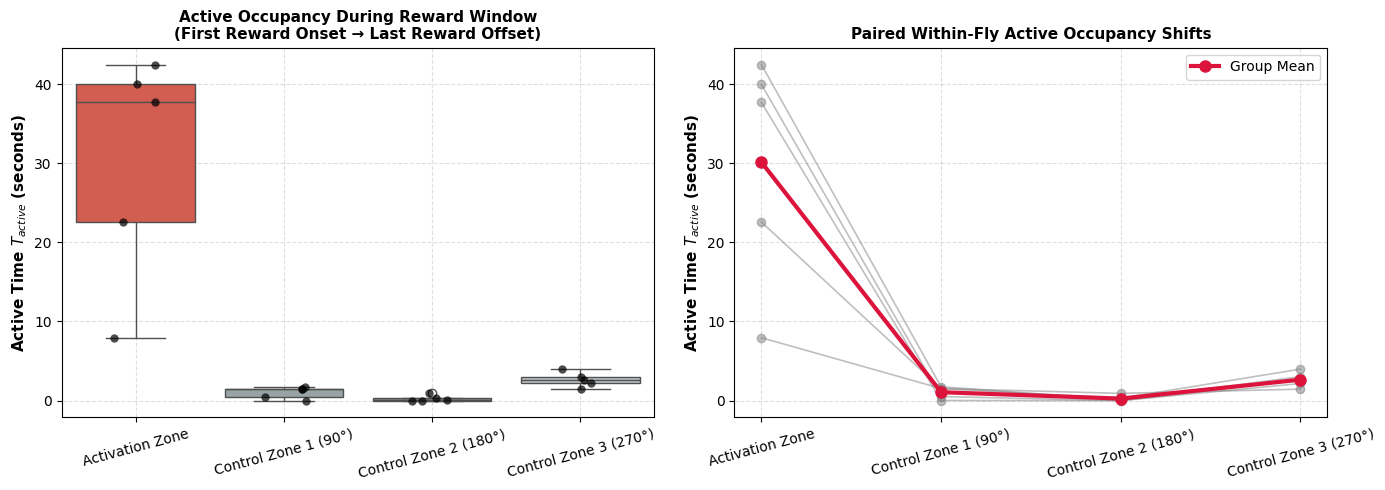

In [58]:
# --- 1. RUN ANALYSIS ON DATASET LISTS ---
df_tactive_exp = analyze_tactive_dataset_list(dataset_Gr43a_ATR_CL_RL, group_label="Gr43a")
df_tactive_ctrl = analyze_tactive_dataset_list(dataset_Gr43a_NR_CL_RU, group_label="Control")
df_tactive_all = pd.concat([df_tactive_exp, df_tactive_ctrl], ignore_index=True)

# --- 2. PLOTTING RAW T_active COMPARISON ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Boxplot with Individual Data Points across Zones
sns.boxplot(
    data=df_tactive_exp, x='Zone', y='T_active_s', ax=axes[0],
    palette=['#e74c3c', '#95a5a6', '#7f8c8d', '#bdc3c7']
)
sns.stripplot(
    data=df_tactive_exp, x='Zone', y='T_active_s', ax=axes[0],
    color='black', alpha=0.7, jitter=0.15, size=6
)
axes[0].set_ylabel('Active Time $T_{active}$ (seconds)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_title('Active Occupancy During Reward Window\n(First Reward Onset → Last Reward Offset)', fontsize=11, fontweight='bold')
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(True, linestyle='--', alpha=0.4)

# Plot B: Within-Fly Paired Trajectories (Activation vs. Control Zones)
pivot_df = df_tactive_exp.pivot(index='fly_id', columns='Zone', values='T_active_s')
zones_order = ['Activation Zone', 'Control Zone 1 (90°)', 'Control Zone 2 (180°)', 'Control Zone 3 (270°)']

for fly_idx in pivot_df.index:
    axes[1].plot(zones_order, pivot_df.loc[fly_idx, zones_order], 'o-', color='gray', alpha=0.5, linewidth=1.2)

# Overlay Group Means
mean_vals = pivot_df[zones_order].mean()
axes[1].plot(zones_order, mean_vals, 'o-', color='crimson', linewidth=3, markersize=8, label='Group Mean')

axes[1].set_ylabel('Active Time $T_{active}$ (seconds)', fontsize=11, fontweight='bold')
axes[1].set_title('Paired Within-Fly Active Occupancy Shifts', fontsize=11, fontweight='bold')
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [28]:
dataset_Gr43a_NR_CL[0].keys()

dict_keys(['file_index', 'uid', 'folder_path', 'df_track', 'zone_X', 'zone_Y', 'zone_r', 'n_rewards', 'first_reward_idx', 'last_reward_idx'])

In [59]:
import numpy as np
import matplotlib.pyplot as plt

def plot_arena_and_zones(exp_dict, arena_r=45.0, zone_r=5.0):
    """
    Plots a 2D spatial schematic of the 45mm arena layout with the 
    Activation Zone and 3 radial-matched control zones.
    """
    act_x = exp_dict['zone_X']
    act_y = exp_dict['zone_Y']
    zone_r = exp_dict['zone_r']
    
    # Radial distance from origin (0,0)
    r_center = np.hypot(act_x, act_y)
    angle_act = np.arctan2(act_y, act_x)
    
    # Compute 3 rotated control zone coordinates
    control_coords = []
    for deg in [90, 180, 270]:
        ang = angle_act + np.radians(deg)
        control_coords.append((r_center * np.cos(ang), r_center * np.sin(ang)))

    fig, ax = plt.subplots(figsize=(7, 7))

    # 1. Arena Outer Perimeter
    arena_circle = plt.Circle((0, 0), arena_r, fill=False, color='black', linewidth=1.8, linestyle='-', label=f'Arena (R={arena_r}mm)')
    ax.add_patch(arena_circle)

    # 2. Dotted Radial Equidistance Ring
    radial_ring = plt.Circle((0, 0), r_center, fill=False, color='gray', linestyle=':', alpha=0.7, label=f'Radial Ring ({r_center:.1f}mm)')
    ax.add_patch(radial_ring)

    # 3. Activation Zone (Red)
    act_circle = plt.Circle((act_x, act_y), zone_r, color='#e74c3c', alpha=0.55, label='Activation Zone')
    ax.add_patch(act_circle)
    ax.text(act_x, act_y, 'Activation\nZone', color='darkred', fontsize=8, ha='center', va='center', fontweight='bold')

    # 4. Control Zones (Grayscale)
    colors = ['#7f8c8d', '#95a5a6', '#bdc3c7']
    for i, (cx, cy) in enumerate(control_coords):
        ctrl_circle = plt.Circle((cx, cy), zone_r, color=colors[i], alpha=0.55, label=f'Control {i+1} ({(i+1)*90}°)')
        ax.add_patch(ctrl_circle)
        ax.text(cx, cy, f'Control {i+1}\n({(i+1)*90}°)', color='black', fontsize=8, ha='center', va='center', fontweight='bold')

    # 5. Center Origin Crosshair
    ax.plot(0, 0, 'k+', markersize=10, markeredgewidth=1.5, label='Origin (0,0)')

    ax.set_xlim(-arena_r - 5, arena_r + 5)
    ax.set_ylim(-arena_r - 5, arena_r + 5)
    ax.set_aspect('equal')
    ax.set_xlabel('X Position (mm)', fontsize=10, fontweight='bold')
    ax.set_ylabel('Y Position (mm)', fontsize=10, fontweight='bold')
    ax.set_title('Arena Geometry & Radial Control Zone Placement', fontsize=12, fontweight='bold')
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.0), fontsize=8)

    plt.tight_layout()
    plt.show()

# Run visualization on an experiment dictionary:
# plot_arena_and_zones(exp_fly_list[0], arena_r=45.0, zone_r=5.0)

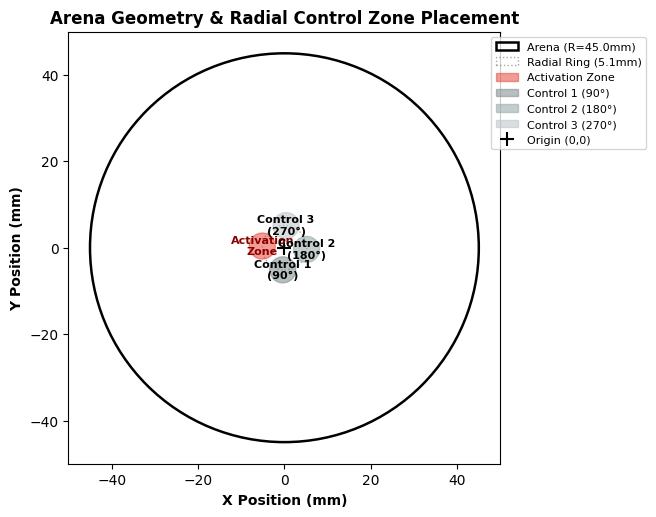

In [92]:
plot_arena_and_zones(dataset_Gr43a_ATR_CL[0])

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def compute_post_reward_occupancy_dict(exp_dict, zone_r=5.0, v_thresh=1.5, fps=60.0):
    """
    Computes both Total Occupancy and Active Occupancy across Activation Zone and 
    3 Radial-Matched Control Zones specifically during the post-reward phase 
    (from last reward LED offset to the end of tracking).
    """
    zone_x = exp_dict['zone_X']
    zone_y = exp_dict['zone_Y']
    zone_r = exp_dict['zone_r']
    df = exp_dict['df_track']
    
    x_col = 'X' if 'X' in df.columns else 'X_cal'
    y_col = 'Y' if 'Y' in df.columns else 'Y_cal'
    v_col = 'Vf_smooth' if 'Vf_smooth' in df.columns else 'Vf'
    
    # Isolate post-reward phase (after last reward offset)
    led_state = df['LEDstate'].values
    reward_offsets = np.where((led_state[:-1] == 1) & (led_state[1:] == 0))[0] + 1
    
    if len(reward_offsets) == 0:
        return None  # No reward triggered in this dataset
        
    last_offset_idx = reward_offsets[-1]
    post_df = df.iloc[last_offset_idx:].copy().reset_index(drop=True)
    
    if len(post_df) == 0:
        return None
        
    # Compute 3 radial-matched control centers (rotated 90°, 180°, 270° around origin)
    r_center = np.hypot(zone_x, zone_y)
    angle_act = np.arctan2(zone_y, zone_x)
    
    control_coords = []
    for deg in [90, 180, 270]:
        ang = angle_act + np.radians(deg)
        control_coords.append((r_center * np.cos(ang), r_center * np.sin(ang)))
        
    # Active locomotion mask
    active_mask = post_df[v_col] > v_thresh if v_col in post_df.columns else np.ones(len(post_df), dtype=bool)
    
    # --- 1. Total Occupancy (Seconds) - Unfiltered ---
    dist_act = np.hypot(post_df[x_col] - zone_x, post_df[y_col] - zone_y)
    t_tot_act = np.sum(dist_act <= zone_r) / fps
    
    t_tot_ctrl = []
    for cx, cy in control_coords:
        dist_ctrl = np.hypot(post_df[x_col] - cx, post_df[y_col] - cy)
        t_tot_ctrl.append(np.sum(dist_ctrl <= zone_r) / fps)
        
    # --- 2. Active Occupancy (Seconds) - Motion filtered ---
    t_active_act = np.sum((dist_act <= zone_r) & active_mask) / fps
    
    t_active_ctrl = []
    for cx, cy in control_coords:
        dist_ctrl = np.hypot(post_df[x_col] - cx, post_df[y_col] - cy)
        t_active_ctrl.append(np.sum((dist_ctrl <= zone_r) & active_mask) / fps)
        
    zone_names = ['Activation Zone', 'Control Zone 1 (90°)', 'Control Zone 2 (180°)', 'Control Zone 3 (270°)']
    
    return {
        'Zone_Names': zone_names,
        'Total_Occupancy_s': [t_tot_act] + t_tot_ctrl,
        'Active_Occupancy_s': [t_active_act] + t_active_ctrl,
        'Post_Reward_Duration_s': len(post_df) / fps
    }

In [63]:
def plot_single_dataset_post_reward_occupancy(exp_dict, zone_r=5.0, v_thresh=1.5):
    """
    Plots side-by-side Total Occupancy and Active Occupancy across all 4 zones 
    during the post-reward period for a single experiment dictionary.
    """
    res = compute_post_reward_occupancy_dict(exp_dict, zone_r=zone_r, v_thresh=v_thresh)
    if res is None:
        print("No reward offsets found in dataset!")
        return

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    zones = res['Zone_Names']
    colors = ['#e74c3c', '#95a5a6', '#7f8c8d', '#bdc3c7']

    # --- Panel 1: Total Occupancy ---
    bars1 = axes[0].bar(zones, res['Total_Occupancy_s'], color=colors, edgecolor='black', alpha=0.85)
    axes[0].set_ylabel('Total Occupancy Time (s)', fontsize=11, fontweight='bold')
    axes[0].set_title(f'Post-Reward Total Occupancy\n(Includes Pauses | Window: {res["Post_Reward_Duration_s"]:.1f}s)', fontsize=11, fontweight='bold')
    axes[0].tick_params(axis='x', rotation=15)
    axes[0].grid(axis='y', linestyle='--', alpha=0.5)

    for bar in bars1:
        yval = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + (0.01 * max(res['Total_Occupancy_s']) if max(res['Total_Occupancy_s'])>0 else 0.1), 
                     f'{yval:.1f}s', ha='center', va='bottom', fontsize=9, fontweight='bold')

    # --- Panel 2: Active Occupancy ---
    bars2 = axes[1].bar(zones, res['Active_Occupancy_s'], color=colors, edgecolor='black', alpha=0.85)
    axes[1].set_ylabel(f'Active Occupancy Time $T_{{active}}$ (s)', fontsize=11, fontweight='bold')
    axes[1].set_title(f'Post-Reward Active Occupancy\n(Discounting Pauses: $V_{{fwd}} > {v_thresh}$ mm/s)', fontsize=11, fontweight='bold')
    axes[1].tick_params(axis='x', rotation=15)
    axes[1].grid(axis='y', linestyle='--', alpha=0.5)

    for bar in bars2:
        yval = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + (0.01 * max(res['Active_Occupancy_s']) if max(res['Active_Occupancy_s'])>0 else 0.1), 
                     f'{yval:.1f}s', ha='center', va='bottom', fontsize=9, fontweight='bold')

    plt.tight_layout()
    plt.show()


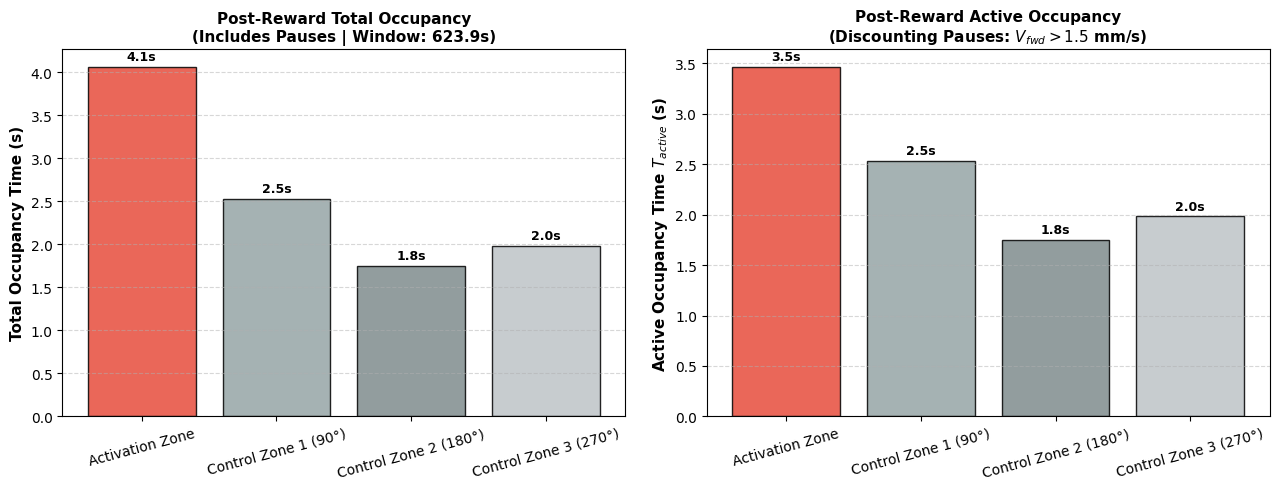

In [68]:

# Example Usage for single dataset:
plot_single_dataset_post_reward_occupancy(dataset_Gr43a_ATR_CL_LL[0])

In [69]:
def plot_population_post_reward_occupancy(list_of_exp_dicts, group_name="Experimental"):
    records = []
    for idx, exp in enumerate(list_of_exp_dicts):
        res = compute_post_reward_occupancy_dict(exp)
        if res is None:
            continue
        for i, zname in enumerate(res['Zone_Names']):
            records.append({
                'fly_id': idx,
                'Zone': zname,
                'Total_Occupancy_s': res['Total_Occupancy_s'][i],
                'Active_Occupancy_s': res['Active_Occupancy_s'][i],
                'Group': group_name
            })
            
    df_pop = pd.DataFrame(records)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Total Occupancy
    sns.boxplot(data=df_pop, x='Zone', y='Total_Occupancy_s', ax=axes[0], palette=['#e74c3c', '#95a5a6', '#7f8c8d', '#bdc3c7'])
    sns.stripplot(data=df_pop, x='Zone', y='Total_Occupancy_s', ax=axes[0], color='black', alpha=0.6, jitter=0.15)
    axes[0].set_title(f'{group_name}: Post-Reward Total Occupancy', fontsize=11, fontweight='bold')
    axes[0].tick_params(axis='x', rotation=15)
    axes[0].grid(axis='y', linestyle='--', alpha=0.5)
    
    # Active Occupancy
    sns.boxplot(data=df_pop, x='Zone', y='Active_Occupancy_s', ax=axes[1], palette=['#e74c3c', '#95a5a6', '#7f8c8d', '#bdc3c7'])
    sns.stripplot(data=df_pop, x='Zone', y='Active_Occupancy_s', ax=axes[1], color='black', alpha=0.6, jitter=0.15)
    axes[1].set_title(f'{group_name}: Post-Reward Active Occupancy', fontsize=11, fontweight='bold')
    axes[1].tick_params(axis='x', rotation=15)
    axes[1].grid(axis='y', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()


/tmp/ipykernel_6097/4159374134.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_pop, x='Zone', y='Total_Occupancy_s', ax=axes[0], palette=['#e74c3c', '#95a5a6', '#7f8c8d', '#bdc3c7'])
/tmp/ipykernel_6097/4159374134.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_pop, x='Zone', y='Active_Occupancy_s', ax=axes[1], palette=['#e74c3c', '#95a5a6', '#7f8c8d', '#bdc3c7'])


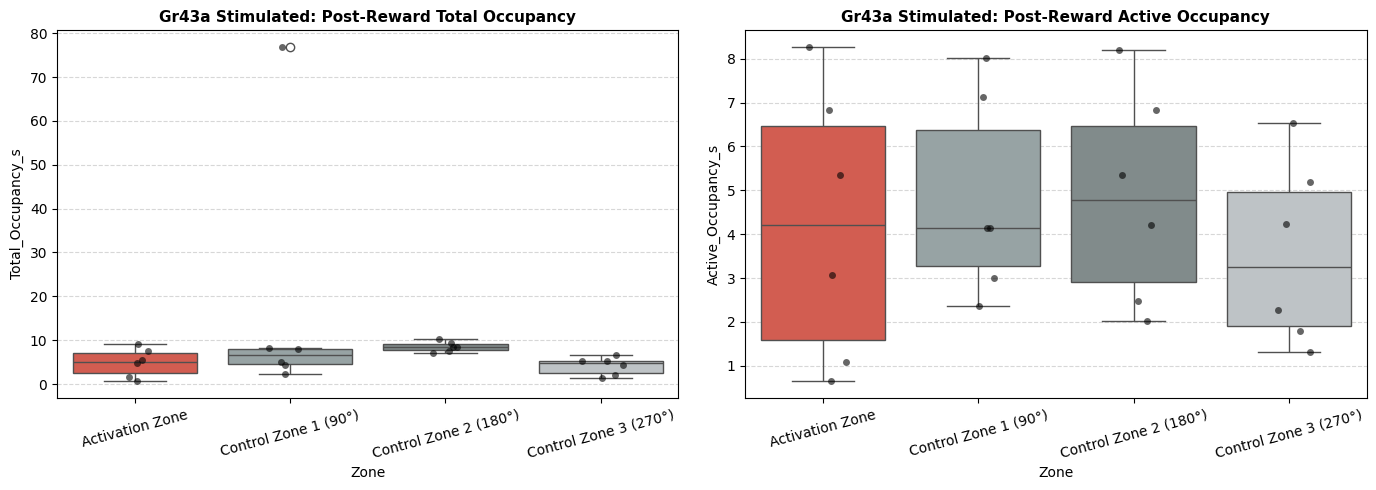

In [75]:

# Example Usage for population:
plot_population_post_reward_occupancy(dataset_Gr43a_ATR_CL_LU, group_name="Gr43a Stimulated")

In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def compute_time_binned_post_reward_occupancy(exp_dict, bin_duration_s=60.0, total_duration_s=300.0, zone_r=5.0, v_thresh=1.5, fps=60.0):
    """
    Bins the post-reward phase into 1-minute time windows (default: first 5 mins / 300s)
    and computes Total Occupancy and Active Occupancy for the Activation Zone and 3 Control Zones.
    """
    zone_x = exp_dict['zone_X']
    zone_y = exp_dict['zone_Y']
    zone_r = exp_dict['zone_r']
    df = exp_dict['df_track']
    
    x_col = 'X' if 'X' in df.columns else 'X_cal'
    y_col = 'Y' if 'Y' in df.columns else 'Y_cal'
    v_col = 'Vf_smooth' if 'Vf_smooth' in df.columns else 'Vf'
    
    # 1. Isolate post-reward phase (strictly after last reward LED offset)
    led_state = df['LEDstate'].values
    reward_offsets = np.where((led_state[:-1] == 1) & (led_state[1:] == 0))[0] + 1
    
    if len(reward_offsets) == 0:
        return None  # No reward triggered
        
    last_offset_idx = reward_offsets[-1]
    post_df = df.iloc[last_offset_idx:].copy().reset_index(drop=True)
    
    # 2. Limit to the first N seconds (e.g., 300s = 5 mins)
    max_frames = int(total_duration_s * fps)
    post_df = post_df.iloc[:max_frames]
    
    if len(post_df) == 0:
        return None
        
    # 3. Compute control zone coordinates (rotated 90°, 180°, 270°)
    r_center = np.hypot(zone_x, zone_y)
    angle_act = np.arctan2(zone_y, zone_x)
    control_coords = [(r_center * np.cos(angle_act + np.radians(deg)), 
                       r_center * np.sin(angle_act + np.radians(deg))) for deg in [90, 180, 270]]
    
    frames_per_bin = int(bin_duration_s * fps)
    n_bins = int(np.ceil(len(post_df) / frames_per_bin))
    
    bin_records = []
    zone_names = ['Activation Zone', 'Control Zone 1 (90°)', 'Control Zone 2 (180°)', 'Control Zone 3 (270°)']
    
    for b in range(n_bins):
        bin_df = post_df.iloc[b * frames_per_bin : (b + 1) * frames_per_bin]
        if len(bin_df) == 0:
            continue
            
        active_mask = bin_df[v_col] > v_thresh if v_col in bin_df.columns else np.ones(len(bin_df), dtype=bool)
        
        # Radial distances
        dist_act = np.hypot(bin_df[x_col] - zone_x, bin_df[y_col] - zone_y)
        dist_ctrls = [np.hypot(bin_df[x_col] - cx, bin_df[y_col] - cy) for cx, cy in control_coords]
        
        # Calculate time spent in zones (seconds)
        t_tot_act = np.sum(dist_act <= zone_r) / fps
        t_active_act = np.sum((dist_act <= zone_r) & active_mask) / fps
        
        t_tot_ctrls = [np.sum(d <= zone_r) / fps for d in dist_ctrls]
        t_active_ctrls = [np.sum((d <= zone_r) & active_mask) / fps for d in dist_ctrls]
        
        tot_occupancies = [t_tot_act] + t_tot_ctrls
        active_occupancies = [t_active_act] + t_active_ctrls
        
        for zn, tot_occ, act_occ in zip(zone_names, tot_occupancies, active_occupancies):
            bin_records.append({
                'bin_idx': b + 1,
                'bin_label': f'Min {b+1}',
                'Zone': zn,
                'Is_Activation_Zone': (zn == 'Activation Zone'),
                'Total_Occupancy_s': tot_occ,
                'Active_Occupancy_s': act_occ
            })
            
    return pd.DataFrame(bin_records)

In [116]:
def plot_binned_post_reward_occupancy(exp_dict, bin_duration_s=60.0, total_duration_s=300.0, v_thresh=1.5):
    """
    Plots time-course curves showing how Total and Active Occupancy decay across 1-minute bins.
    """
    df_binned = compute_time_binned_post_reward_occupancy(
        exp_dict, bin_duration_s=bin_duration_s, total_duration_s=total_duration_s, v_thresh=v_thresh
    )
    
    if df_binned is None or len(df_binned) == 0:
        print("Insufficient post-reward tracking data.")
        return

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    palette = {
        'Activation Zone': '#e74c3c', 
        'Control Zone 1 (90°)': '#7f8c8d', 
        'Control Zone 2 (180°)': '#95a5a6', 
        'Control Zone 3 (270°)': '#bdc3c7'
    }

    # --- Panel 1: Total Occupancy Dynamic ---
    sns.lineplot(
        data=df_binned, x='bin_label', y='Total_Occupancy_s', hue='Zone', 
        palette=palette, marker='o', linewidth=2.5, markersize=8, ax=axes[0]
    )
    axes[0].set_ylabel('Total Occupancy Time (s / min)', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Time Bin (Post-Reward Washout)', fontsize=11, fontweight='bold')
    axes[0].set_title('Post-Reward Total Occupancy Decay\n(Includes Pauses)', fontsize=12, fontweight='bold')
    axes[0].grid(True, linestyle='--', alpha=0.5)

    # --- Panel 2: Active Occupancy Dynamic ---
    sns.lineplot(
        data=df_binned, x='bin_label', y='Active_Occupancy_s', hue='Zone', 
        palette=palette, marker='s', linewidth=2.5, markersize=8, ax=axes[1]
    )
    axes[1].set_ylabel(f'Active Occupancy Time $T_{{active}}$ (s / min)', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Time Bin (Post-Reward Washout)', fontsize=11, fontweight='bold')
    axes[1].set_title(f'Post-Reward Active Occupancy Decay\n(Discounting Pauses: $V_{{fwd}} > {v_thresh}$ mm/s)', fontsize=12, fontweight='bold')
    axes[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()


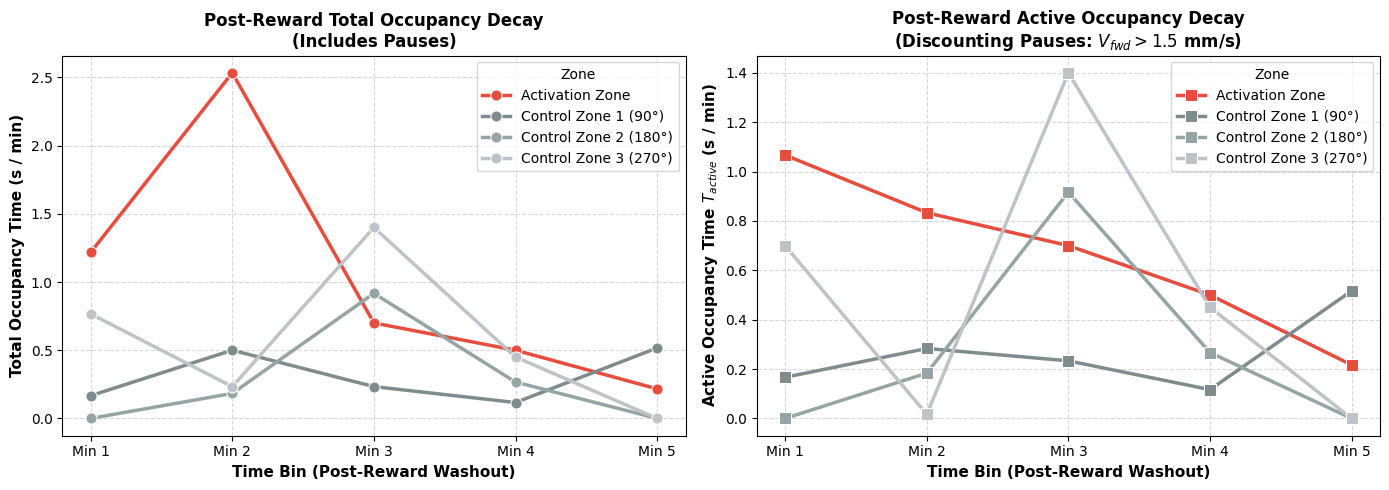

In [143]:

# Example Usage for single dataset:
plot_binned_post_reward_occupancy(dataset_Gr43a_ATR_CL_RL[3])

In [118]:
def plot_population_binned_post_reward_occupancy(list_of_exp_dicts, group_label="Experimental"):
    pop_list = []
    for idx, exp in enumerate(list_of_exp_dicts):
        df_b = compute_time_binned_post_reward_occupancy(exp)
        if df_b is not None:
            df_b['fly_id'] = idx
            pop_list.append(df_b)
            
    if not pop_list:
        print("No valid datasets extracted.")
        return
        
    df_pop = pd.concat(pop_list, ignore_index=True)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    palette = {
        'Activation Zone': '#e74c3c', 
        'Control Zone 1 (90°)': '#7f8c8d', 
        'Control Zone 2 (180°)': '#95a5a6', 
        'Control Zone 3 (270°)': '#bdc3c7'
    }

    # Total Occupancy Mean +- SEM
    sns.lineplot(
        data=df_pop, x='bin_label', y='Total_Occupancy_s', hue='Zone', 
        palette=palette, marker='o', errorbar='se', linewidth=2.5, ax=axes[0]
    )
    axes[0].set_ylabel('Mean Total Occupancy (s / min)', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Time Bin (Post-Reward)', fontsize=11, fontweight='bold')
    axes[0].set_title(f'{group_label}: Total Occupancy Time-Course (Mean ± SEM)', fontsize=11, fontweight='bold')
    axes[0].grid(True, linestyle='--', alpha=0.5)

    # Active Occupancy Mean +- SEM
    sns.lineplot(
        data=df_pop, x='bin_label', y='Active_Occupancy_s', hue='Zone', 
        palette=palette, marker='s', errorbar='se', linewidth=2.5, ax=axes[1]
    )
    axes[1].set_ylabel('Mean Active Occupancy (s / min)', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Time Bin (Post-Reward)', fontsize=11, fontweight='bold')
    axes[1].set_title(f'{group_label}: Active Occupancy Time-Course (Mean ± SEM)', fontsize=11, fontweight='bold')
    axes[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()


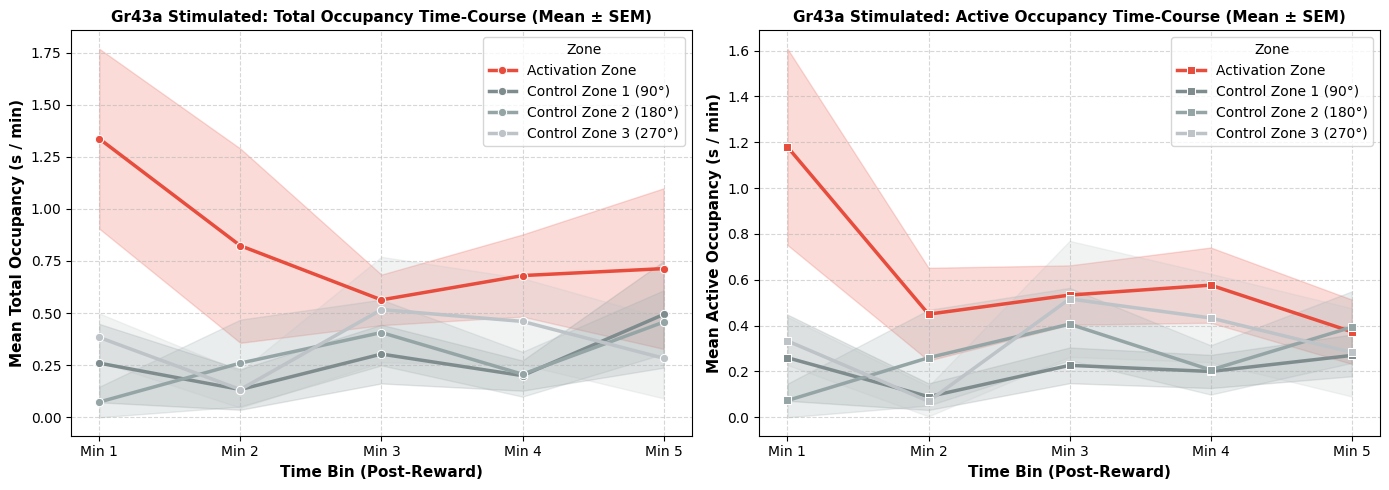

In [119]:

# Example Usage for population:
plot_population_binned_post_reward_occupancy(dataset_Gr43a_ATR_CL_RL, group_label="Gr43a Stimulated")

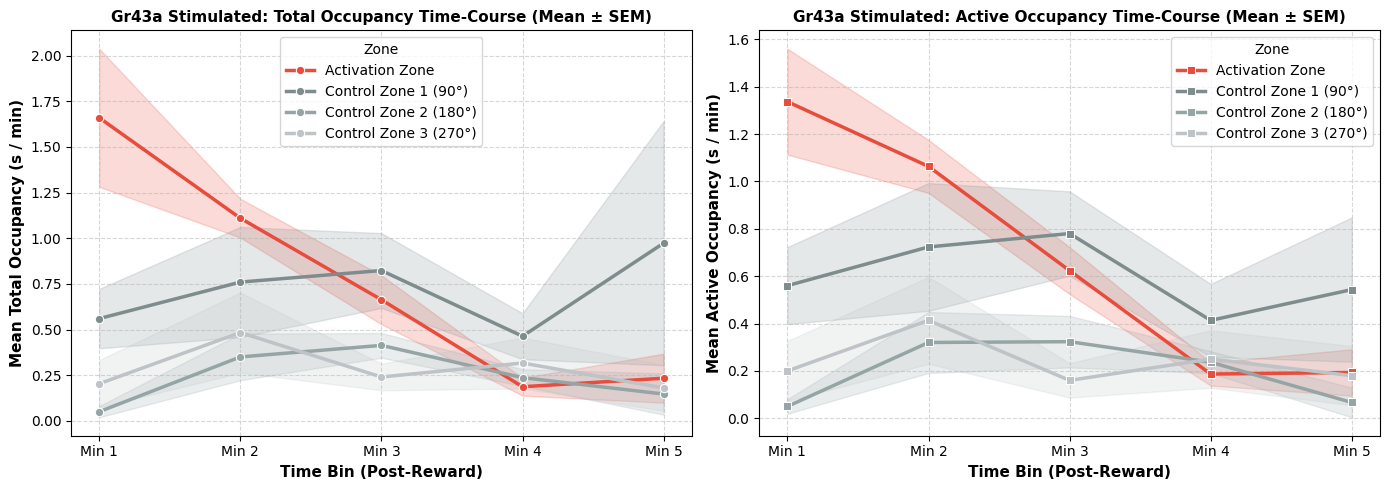

In [120]:

# Example Usage for population:
plot_population_binned_post_reward_occupancy(dataset_Gr43a_ATR_CL_LL, group_label="Gr43a Stimulated")

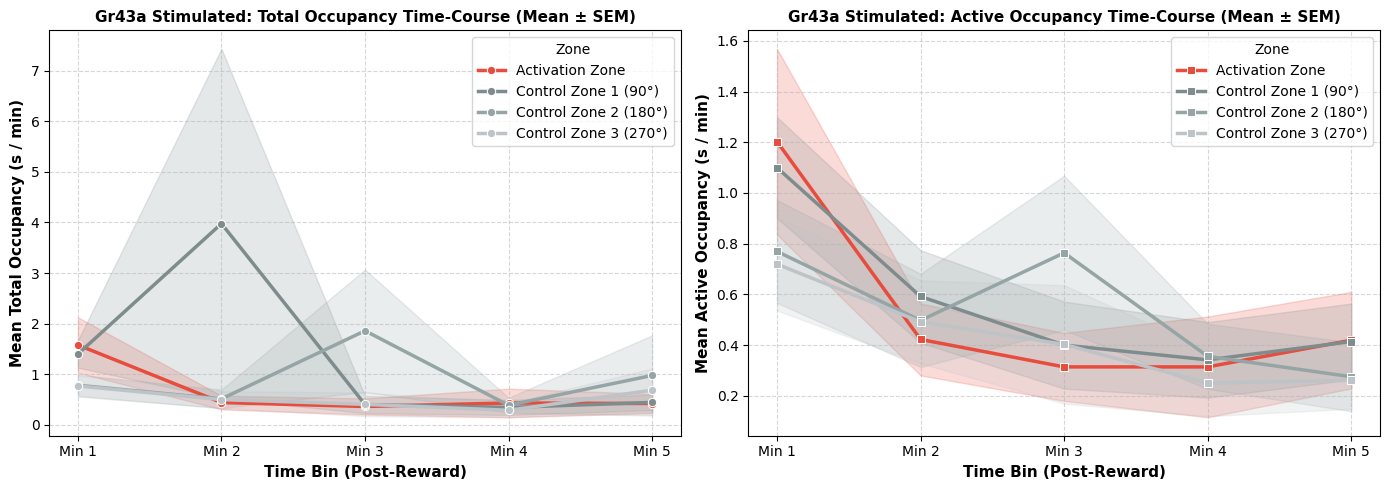

In [121]:

# Example Usage for population:
plot_population_binned_post_reward_occupancy(dataset_Gr43a_ATR_CL_LU, group_label="Gr43a Stimulated")

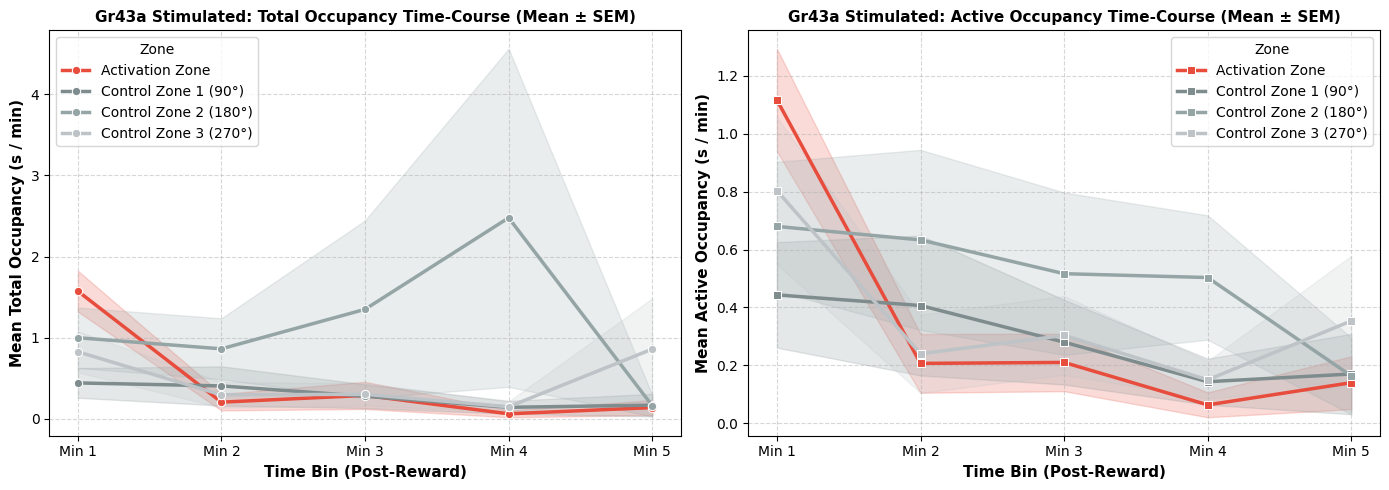

In [122]:

# Example Usage for population:
plot_population_binned_post_reward_occupancy(dataset_Gr43a_ATR_CL_RU, group_label="Gr43a Stimulated")

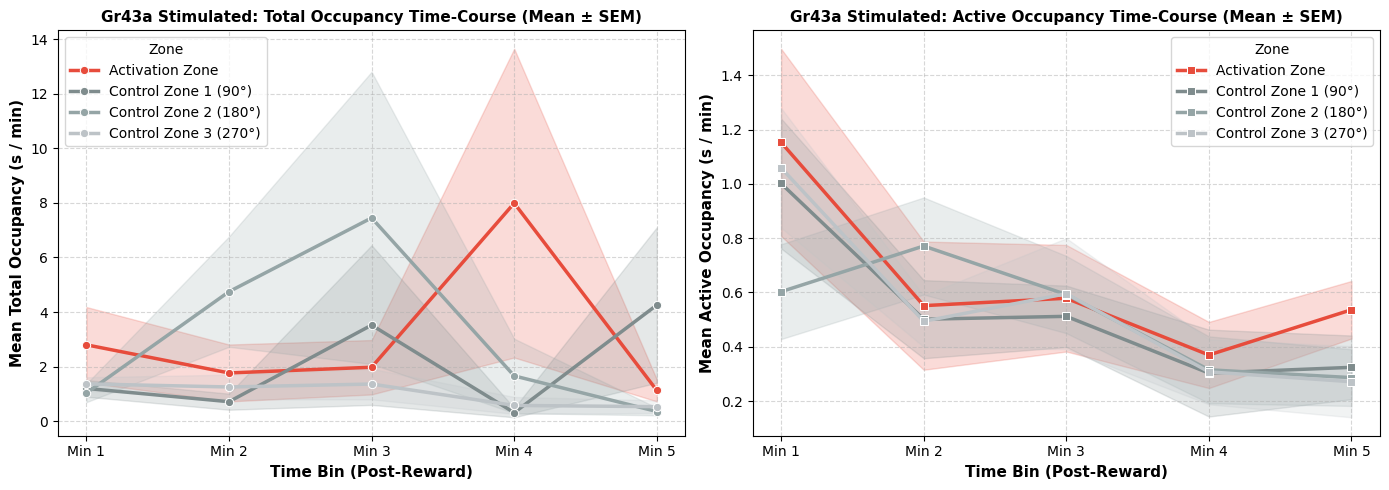

In [144]:

# Example Usage for population:
plot_population_binned_post_reward_occupancy(dataset_Gr43a_ATR_CL, group_label="Gr43a Stimulated")

In [38]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def compute_polar_maps(
    exp_list: list,
    r_edges: np.ndarray = np.linspace(0, 25, 25),  # Radial bins (mm)
    phi_edges: np.ndarray = np.linspace(-np.pi, np.pi, 25),  # Polar angle bins
    fps: float = 60.0,
):
    """Computes polar maps of relative heading orientation and angular velocity (|Vr|)

    centered on the reward origin (zone_X, zone_Y).
    """
    num_r = len(r_edges) - 1
    num_phi = len(phi_edges) - 1

    # Accumulators for circular mean of relative heading
    sin_sum = np.zeros((num_r, num_phi))
    cos_sum = np.zeros((num_r, num_phi))

    # Accumulators for mean absolute rotational velocity |Vr|
    vr_sum = np.zeros((num_r, num_phi))
    count_matrix = np.zeros((num_r, num_phi))

    for exp in exp_list:
        df_track = exp.get("df_track", None)
        zone_x = exp.get("zone_X", 0.0)
        zone_y = exp.get("zone_Y", 0.0)

        if df_track is None or "LEDstate" not in df_track.columns:
            continue

        led_states = df_track["LEDstate"].values
        led_diff = np.diff(led_states, prepend=0)
        offsets = np.where(led_diff == -1)[0]
        onsets = np.where(led_diff == 1)[0]

        for off_idx in offsets:
            next_on = onsets[onsets > off_idx]
            if len(next_on) == 0:
                continue

            # Exclude visual startle window (first 1s)
            start = off_idx + int(1.0 * fps)
            end = next_on[0]
            if end - start < int(1.0 * fps):
                continue

            x = df_track["X"].iloc[start:end].values - zone_x
            y = df_track["Y"].iloc[start:end].values - zone_y
            ori_deg = df_track["ori_angle_cal"].iloc[start:end].values
            vr = np.abs(
                df_track["Vr_smooth"].iloc[start:end].values
            )  # Absolute angular velocity

            # Convert to Polar coordinates relative to origin
            r = np.sqrt(x**2 + y**2)
            phi = np.arctan2(y, x)  # Angle of position vector from origin

            # Compute relative heading: orientation relative to target origin
            ori_rad = np.deg2rad(ori_deg)
            target_angle = np.arctan2(-y, -x)  # Vector pointing back to origin
            rel_heading = np.arctan2(
                np.sin(ori_rad - target_angle), np.cos(ori_rad - target_angle)
            )

            # Bin indices
            r_idx = np.digitize(r, r_edges) - 1
            phi_idx = np.digitize(phi, phi_edges) - 1

            # Accumulate into grid
            valid = (
                (r_idx >= 0)
                & (r_idx < num_r)
                & (phi_idx >= 0)
                & (phi_idx < num_phi)
            )

            for ri, pi, rh, v_rot in zip(
                r_idx[valid], phi_idx[valid], rel_heading[valid], vr[valid]
            ):
                sin_sum[ri, pi] += np.sin(rh)
                cos_sum[ri, pi] += np.cos(rh)
                vr_sum[ri, pi] += v_rot
                count_matrix[ri, pi] += 1

    # Mask unvisited bins
    mask = count_matrix < 5
    count_matrix[mask] = np.nan

    # Mean relative heading (circular mean)
    mean_rel_heading = np.arctan2(sin_sum, cos_sum)
    mean_rel_heading[mask] = np.nan

    # Mean angular velocity |Vr|
    mean_vr = vr_sum / count_matrix

    return mean_rel_heading, mean_vr, r_edges, phi_edges

In [39]:
def plot_polar_analysis(
    rel_heading_atr,
    vr_atr,
    rel_heading_nr,
    vr_nr,
    r_edges,
    phi_edges,
):
    """Plots 2D polar maps comparing ATR and NR control flies."""
    r_centers = 0.5 * (r_edges[:-1] + r_edges[1:])
    phi_centers = 0.5 * (phi_edges[:-1] + phi_edges[1:])
    R, PHI = np.meshgrid(r_centers, phi_centers, indexing="ij")

    # Cartesian coordinates for quiver vector endpoints
    X = R * np.cos(PHI)
    Y = R * np.sin(PHI)

    fig, axes = plt.subplots(
        2, 2, figsize=(12, 10), subplot_kw={"projection": "polar"}
    )

    # 1. ATR Angular Velocity |Vr| Map
    mesh1 = axes[0, 0].pcolormesh(
        PHI, R, vr_atr, cmap="magma", shading="nearest"
    )
    axes[0, 0].set_title("ATR: Angular Velocity |Vr| (deg/s)", pad=15)
    fig.colorbar(mesh1, ax=axes[0, 0], shrink=0.7)

    # 2. NR Angular Velocity |Vr| Map
    mesh2 = axes[0, 1].pcolormesh(PHI, R, vr_nr, cmap="magma", shading="nearest")
    axes[0, 1].set_title("NR Control: Angular Velocity |Vr| (deg/s)", pad=15)
    fig.colorbar(mesh2, ax=axes[0, 1], shrink=0.7)

    # 3. ATR Heading Orientation Field
    U_atr = np.cos(rel_heading_atr)
    V_atr = np.sin(rel_heading_atr)
    axes[1, 0].quiver(
        PHI,
        R,
        U_atr,
        V_atr,
        color="crimson",
        pivot="middle",
        scale=25,
        headwidth=3,
    )
    axes[1, 0].set_title(
        "ATR: Heading Alignment Relative to Origin", pad=15
    )

    # 4. NR Heading Orientation Field
    U_nr = np.cos(rel_heading_nr)
    V_nr = np.sin(rel_heading_nr)
    axes[1, 1].quiver(
        PHI, R, U_nr, V_nr, color="gray", pivot="middle", scale=25, headwidth=3
    )
    axes[1, 1].set_title(
        "NR Control: Heading Alignment Relative to Origin", pad=15
    )

    plt.tight_layout()
    plt.show()


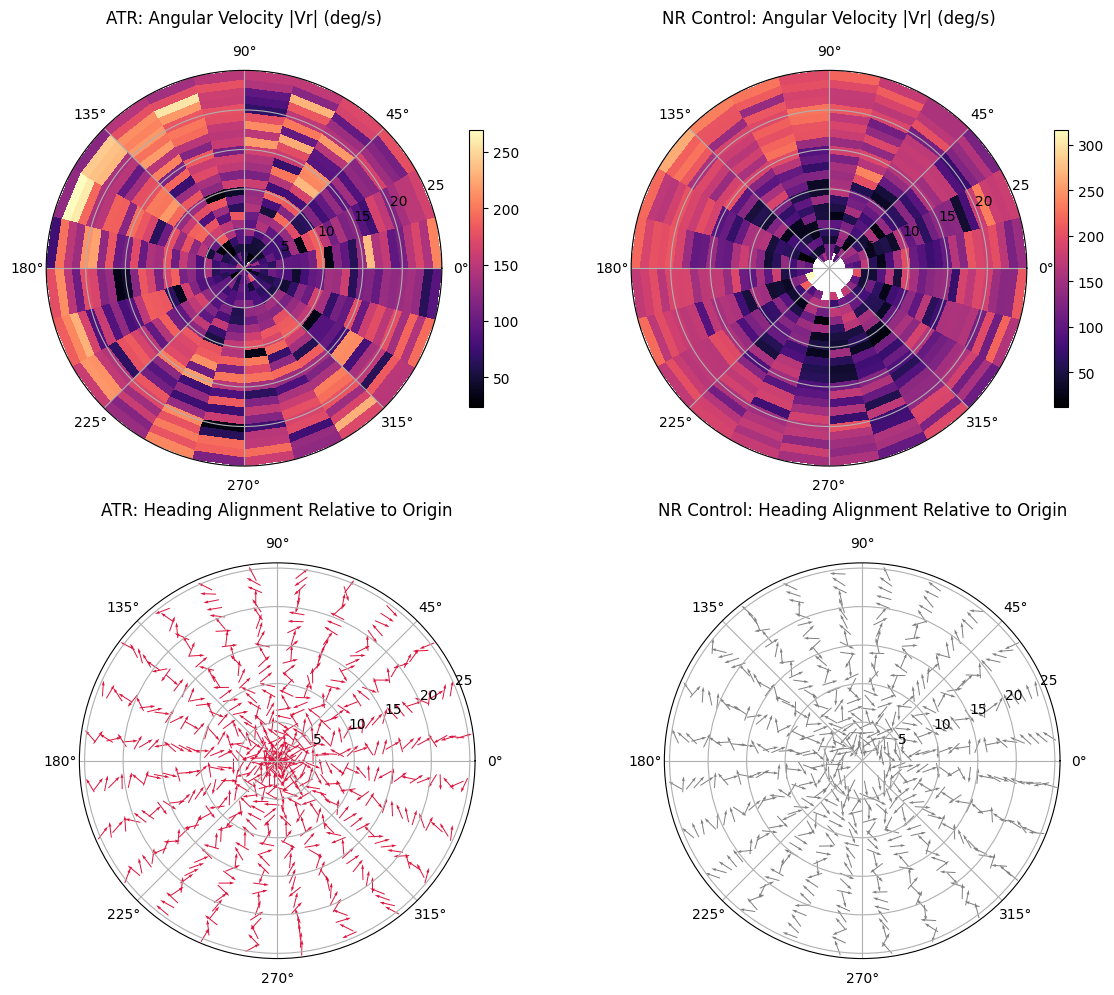

In [40]:


# Run Polar Mapping
heading_atr, vr_atr, r_e, p_e = compute_polar_maps(dataset_Gr43a_ATR_CL)
heading_nr, vr_nr, _, _ = compute_polar_maps(dataset_Gr43a_NR_CL)

plot_polar_analysis(heading_atr, vr_atr, heading_nr, vr_nr, r_e, p_e)

In [44]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def compute_radial_kinematics(
    exp_list: list,
    r_bins: np.ndarray = np.linspace(0, 45, 21),  # 5 mm bins from 0 to 100 mm
    fps: float = 60.0,
) -> pd.DataFrame:
    """Bins Vf, |Vr|, and relative heading orientation by radial distance R from the reward center."""
    records = []

    for exp in exp_list:
        df_track = exp.get("df_track", None)
        zone_x = exp.get("zone_X", 0.0)
        zone_y = exp.get("zone_Y", 0.0)

        if df_track is None or "LEDstate" not in df_track.columns:
            continue

        led_states = df_track["LEDstate"].values
        led_diff = np.diff(led_states, prepend=0)
        offsets = np.where(led_diff == -1)[0]
        onsets = np.where(led_diff == 1)[0]

        for off_idx in offsets:
            next_on = onsets[onsets > off_idx]
            if len(next_on) == 0:
                continue

            # Skip visual startle window (first 1.0 sec)
            start = off_idx + int(1.0 * fps)
            end = next_on[0]
            if end - start < int(1.0 * fps):
                continue

            # Positions relative to reward origin
            x = df_track["X"].iloc[start:end].values - zone_x
            y = df_track["Y"].iloc[start:end].values - zone_y
            vf = df_track["Vf_smooth"].iloc[start:end].values
            vr = np.abs(df_track["Vr_smooth"].iloc[start:end].values)
            ori_deg = df_track["ori_angle_cal"].iloc[start:end].values

            # Radial distance R
            r = np.sqrt(x**2 + y**2)

            # Angle pointing from current position BACK to reward center
            angle_to_origin = np.arctan2(-y, -x)
            ori_rad = np.deg2rad(ori_deg)

            # Angular difference: 0 deg = facing center, 180 deg = facing away
            rel_heading = np.abs(
                np.arctan2(
                    np.sin(ori_rad - angle_to_origin),
                    np.cos(ori_rad - angle_to_origin),
                )
            )
            rel_heading_deg = np.rad2deg(rel_heading)

            # Bin data by radial distance R
            bin_indices = np.digitize(r, r_bins) - 1

            for bi in range(len(r_bins) - 1):
                mask = bin_indices == bi
                if np.sum(mask) > 0:
                    records.append({
                        "r_bin_center": 0.5 * (r_bins[bi] + r_bins[bi + 1]),
                        "Vf": np.mean(vf[mask]),
                        "Vr_abs": np.mean(vr[mask]),
                        "rel_heading_deg": np.mean(rel_heading_deg[mask]),
                    })

    return pd.DataFrame(records)



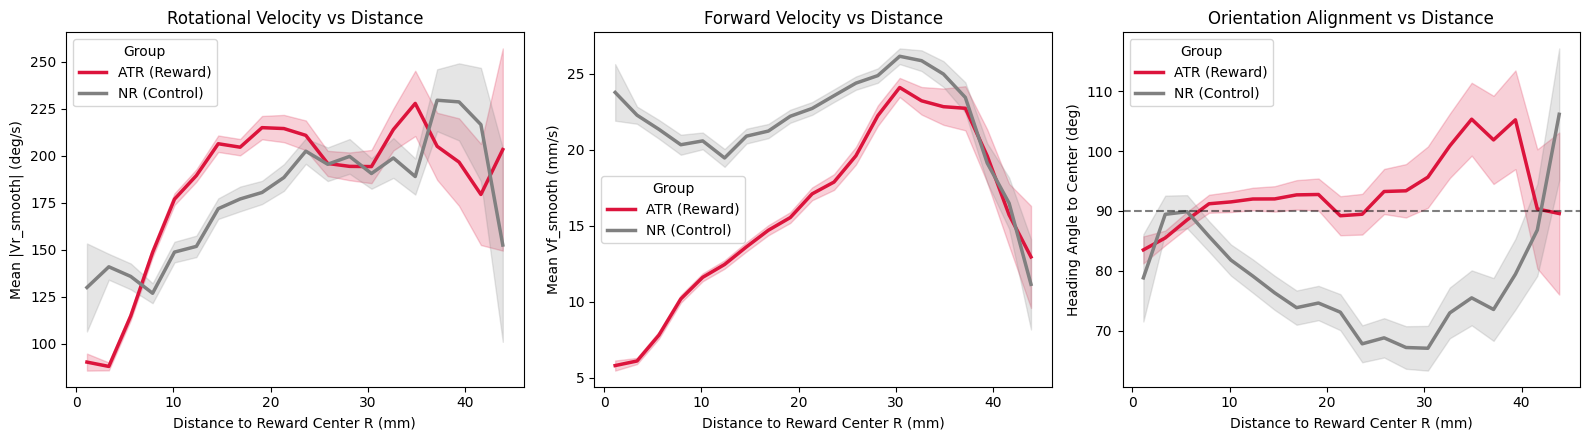

In [46]:


# 1. Run radial extraction for both groups
df_kin_atr = compute_radial_kinematics(dataset_Gr5a_ATR_CL)
df_kin_nr = compute_radial_kinematics(dataset_Gr5a_NR_CL)

df_kin_atr["Group"] = "ATR (Reward)"
df_kin_nr["Group"] = "NR (Control)"
df_radial = pd.concat([df_kin_atr, df_kin_nr], ignore_index=True)

# 2. Plotting Kinematics vs Radial Distance
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)

palette = ["crimson", "gray"]

# Plot 1: Absolute Angular Velocity |Vr|
sns.lineplot(
    data=df_radial,
    x="r_bin_center",
    y="Vr_abs",
    hue="Group",
    palette=palette,
    ax=axes[0],
    errorbar="se",
    lw=2.5,
)
axes[0].set_ylabel("Mean |Vr_smooth| (deg/s)")
axes[0].set_xlabel("Distance to Reward Center R (mm)")
axes[0].set_title("Rotational Velocity vs Distance")

# Plot 2: Forward Velocity Vf
sns.lineplot(
    data=df_radial,
    x="r_bin_center",
    y="Vf",
    hue="Group",
    palette=palette,
    ax=axes[1],
    errorbar="se",
    lw=2.5,
)
axes[1].set_ylabel("Mean Vf_smooth (mm/s)")
axes[1].set_xlabel("Distance to Reward Center R (mm)")
axes[1].set_title("Forward Velocity vs Distance")

# Plot 3: Relative Heading Angle
sns.lineplot(
    data=df_radial,
    x="r_bin_center",
    y="rel_heading_deg",
    hue="Group",
    palette=palette,
    ax=axes[2],
    errorbar="se",
    lw=2.5,
)
axes[2].axhline(
    90, color="black", linestyle="--", alpha=0.5, label="Random Alignment (90°)"
)
axes[2].set_ylabel("Heading Angle to Center (deg)")
axes[2].set_xlabel("Distance to Reward Center R (mm)")
axes[2].set_title("Orientation Alignment vs Distance")

plt.tight_layout()
plt.show()

In [55]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def compute_polar_vr_map(
    exp_list: list,
    r_edges: np.ndarray = np.linspace(0, 45, 21),  # Radial bins (0 to 100 mm)
    phi_edges: np.ndarray = np.linspace(
        -np.pi, np.pi, 37
    ),  # Polar angle bins (10 deg steps)
    fps: float = 60.0,
    min_samples_per_bin: int = 5,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Computes a 2D polar grid where each bin (R, Phi) holds the mean absolute Vr_smooth."""
    num_r = len(r_edges) - 1
    num_phi = len(phi_edges) - 1

    vr_sum = np.zeros((num_r, num_phi))
    count_matrix = np.zeros((num_r, num_phi))

    for exp in exp_list:
        df_track = exp.get("df_track", None)
        zone_x = exp.get("zone_X", 0.0)
        zone_y = exp.get("zone_Y", 0.0)

        if df_track is None or "LEDstate" not in df_track.columns:
            continue

        led_states = df_track["LEDstate"].values
        led_diff = np.diff(led_states, prepend=0)
        offsets = np.where(led_diff == -1)[0]
        onsets = np.where(led_diff == 1)[0]

        for off_idx in offsets:
            next_on = onsets[onsets > off_idx]
            if len(next_on) == 0:
                continue

            # Skip visual startle window (first 1.0 s)
            start = off_idx + int(1.0 * fps)
            end = next_on[0]
            if end - start < int(1.0 * fps):
                continue

            # Positions relative to activation zone center
            x = df_track["X"].iloc[start:end].values - zone_x
            y = df_track["Y"].iloc[start:end].values - zone_y

            # Extract absolute rotational velocity
            if "Vr_abs" in df_track.columns:
                vr = df_track["Vr_abs"].iloc[start:end].values
            else:
                vr = np.abs(df_track["Vr_smooth"].iloc[start:end].values)

            # Polar coordinates relative to activation zone center
            r = np.sqrt(x**2 + y**2)
            phi = np.arctan2(y, x)  # [-pi, pi]

            # Binning
            r_idx = np.digitize(r, r_edges) - 1
            phi_idx = np.digitize(phi, phi_edges) - 1

            valid = (
                (r_idx >= 0)
                & (r_idx < num_r)
                & (phi_idx >= 0)
                & (phi_idx < num_phi)
            )

            # Accumulate values
            for ri, pi, v_rot in zip(
                r_idx[valid], phi_idx[valid], vr[valid]
            ):
                vr_sum[ri, pi] += v_rot
                count_matrix[ri, pi] += 1

    # Calculate mean |Vr| per bin
    mean_vr_map = np.full((num_r, num_phi), np.nan)
    valid_bins = count_matrix >= min_samples_per_bin
    mean_vr_map[valid_bins] = (
        vr_sum[valid_bins] / count_matrix[valid_bins]
    )

    return mean_vr_map, r_edges, phi_edges


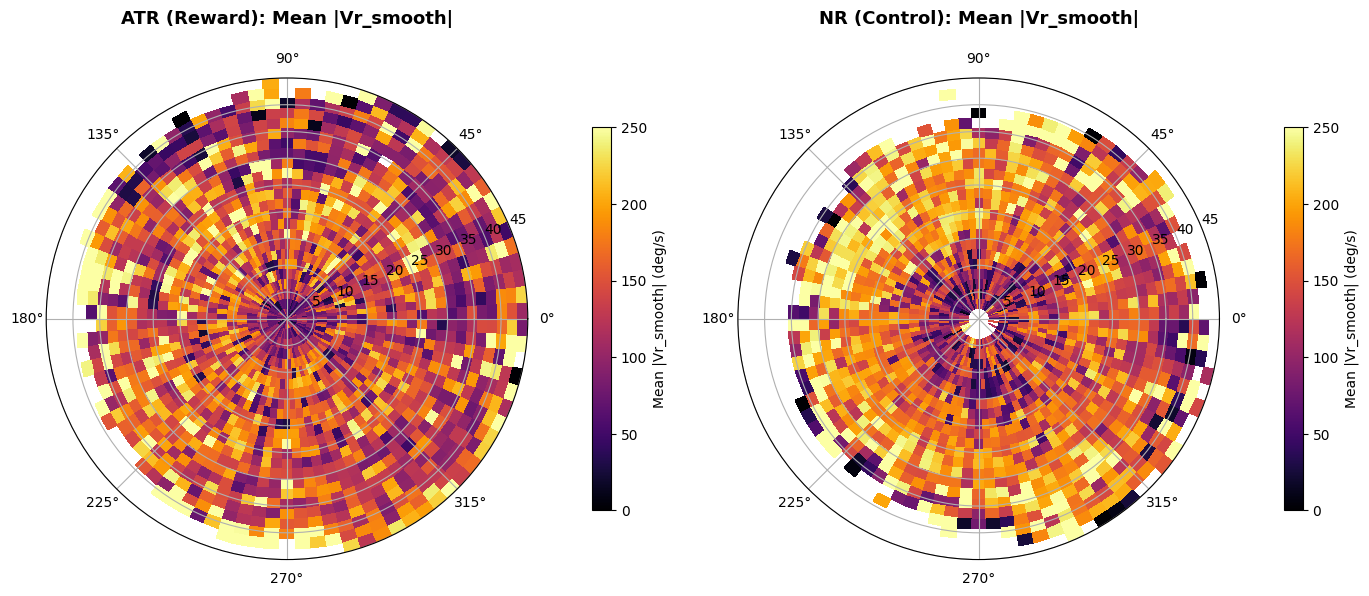

In [66]:


# 1. Define bin edges
r_edges = np.linspace(0, 45, 25)  # 0 to 100 mm
phi_edges = np.linspace(-np.pi, np.pi, 91)  # 36 polar angular sectors

# 2. Compute maps for ATR and NR groups
map_atr, r_e, p_e = compute_polar_vr_map(dataset_Gr43a_ATR_CL, r_edges, phi_edges)
map_nr, _, _ = compute_polar_vr_map(dataset_Gr43a_NR_CL, r_edges, phi_edges)

# 3. Create Polar Meshgrid for Plotting
R, PHI = np.meshgrid(r_e, p_e)  # Shape: (num_phi+1, num_r+1)

# 4. Plotting Side-by-Side Polar Heatmaps
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
    subplot_kw={"projection": "polar"},
)

# Shared color limits based on 95th percentile to allow fair visual comparison
vmax = np.nanpercentile(np.vstack([map_atr, map_nr]), 95)
vmin = np.nanmin([np.nanmin(map_atr), np.nanmin(map_nr)])

# ATR Plot
mesh1 = axes[0].pcolormesh(
    PHI,
    R,
    map_atr.T,  # Transpose so shape matches (num_phi, num_r)
    cmap="inferno",
    vmin=vmin,
    vmax=vmax,
    shading="flat",
)
axes[0].set_title(
    "ATR (Reward): Mean |Vr_smooth|", fontsize=13, pad=20, weight="bold"
)
axes[0].set_theta_zero_location("E")  # 0 degrees to the right
cbar1 = fig.colorbar(mesh1, ax=axes[0], pad=0.1, shrink=0.7)
cbar1.set_label("Mean |Vr_smooth| (deg/s)")

# NR Control Plot
mesh2 = axes[1].pcolormesh(
    PHI,
    R,
    map_nr.T,
    cmap="inferno",
    vmin=vmin,
    vmax=vmax,
    shading="flat",
)
axes[1].set_title(
    "NR (Control): Mean |Vr_smooth|", fontsize=13, pad=20, weight="bold"
)
axes[1].set_theta_zero_location("E")
cbar2 = fig.colorbar(mesh2, ax=axes[1], pad=0.1, shrink=0.7)
cbar2.set_label("Mean |Vr_smooth| (deg/s)")

plt.tight_layout()
plt.show()